In [1]:
import sys
from pathlib import Path

import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.spatial import ConvexHull

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            root / "Code" / "Code_AR_processes",
            root,
        )
        if (candidate / "functions.py").is_file()
        and (candidate / "plotting_functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError(
        "Could not locate Code/Code_AR_processes from the current directory."
    )
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

AR_IMAGES_DIR = AR_CODE_DIR / "outputs" / "images"
EXPERIMENT_OVERVIEWS_DIR = AR_IMAGES_DIR / "experiment_overviews"
MINIMUM_WIDTH_IMAGES_DIR = AR_IMAGES_DIR / "minimum_width"
ORDER_SELECTION_IMAGES_DIR = AR_IMAGES_DIR / "order_selection"
AR_IMAGE_DIRECTORIES = [
    EXPERIMENT_OVERVIEWS_DIR,
    MINIMUM_WIDTH_IMAGES_DIR,
    *(ORDER_SELECTION_IMAGES_DIR / name for name in ("ar1", "ar2", "ar3", "cross_process")),
]
for image_directory in AR_IMAGE_DIRECTORIES:
    image_directory.mkdir(parents=True, exist_ok=True)

plt.style.use(style="seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)


In [2]:
import importlib

from Code.Code_AR_processes import functions as ar_functions

ar_functions = importlib.reload(ar_functions)

from Code.Code_AR_processes.functions import (
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
    ar_impulse_response,
    projected_subgradient_empirical_width,
    batched_geometric_width_curves,
    theoretical_ar_width_in_direction,
    population_minimizing_ar2_direction,
    horizontal_tail_lad_selector,
    aic_bic_ar_order,
    yule_walker_pacf,
    pacf_cutoff_order,
    theoretical_width_2d_from_angle,
    ar_window_zonotope_generators,
    zonotope_polygon_2d,
    fibonacci_sphere_directions,
    zonotope_support_points,
)

phi: [-1.0876 -0.9523]


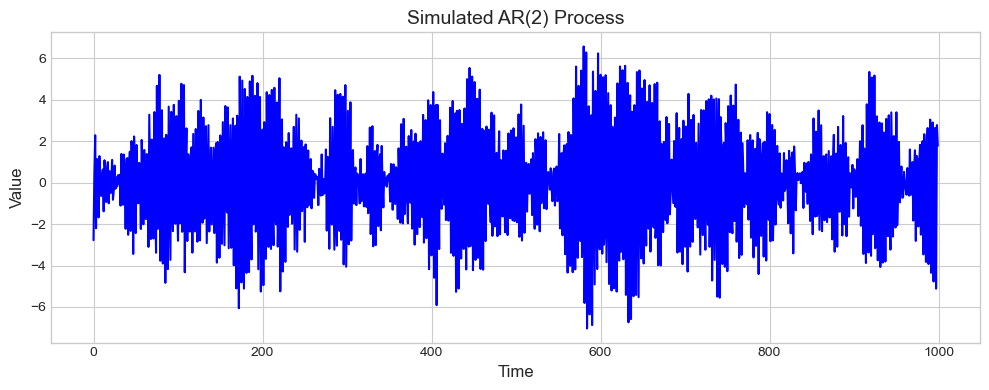

In [3]:
p = 2
coefficient_seed = 42
process_seed = 20260806
sample_size = 1000
burnin = 500
innovations_half_width = 1.0

phi = jones_ar_coefficients(p, rng=coefficient_seed, return_pacf=False)
ar_series = simulate_uniform_ar(phi, sample_size, burnin, innovations_half_width, rng=process_seed)

print("phi:", phi)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ar_series, color="blue", linewidth=1.5)
ax.set_title(f"Simulated AR({p}) Process", fontsize=14)
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
plt.tight_layout()
plt.show()

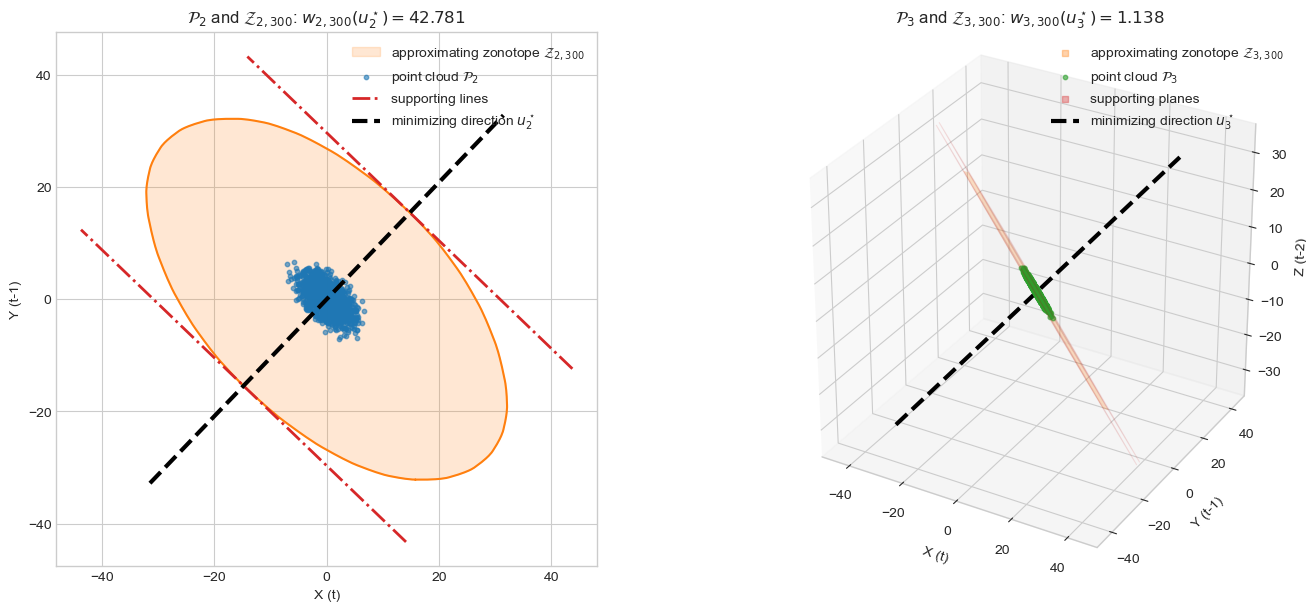

In [4]:
cloud_2d = sliding_window_point_cloud(ar_series, embedding_dimension=2)
cloud_3d = sliding_window_point_cloud(ar_series, embedding_dimension=3)

subgradient_2d = projected_subgradient_empirical_width(
    cloud_2d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260806,
)
subgradient_3d = projected_subgradient_empirical_width(
    cloud_3d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260807,
)

theoretical_history = 10_000
psi_for_cloud_plot = ar_impulse_response(phi, theoretical_history)
psi_shifted_once = np.concatenate(([0.0], psi_for_cloud_plot[:-1]))

angle_grid = np.linspace(0.0, np.pi, 721, endpoint=False)
width_grid = np.array([
    theoretical_width_2d_from_angle(
        angle, psi_for_cloud_plot, psi_shifted_once,
        innovations_half_width,
    )
    for angle in angle_grid
])
best_grid_angle = angle_grid[np.argmin(width_grid)]
theoretical_fit_2d = minimize(
    lambda angle: theoretical_width_2d_from_angle(
        float(angle[0]), psi_for_cloud_plot, psi_shifted_once,
        innovations_half_width,
    ),
    x0=np.array([best_grid_angle]),
    method="Nelder-Mead",
    options={"xatol": 1e-12, "fatol": 1e-12},
)
theoretical_angle_2d = float(theoretical_fit_2d.x[0] % np.pi)
theoretical_direction_2d = np.array([
    np.cos(theoretical_angle_2d),
    np.sin(theoretical_angle_2d),
])
theoretical_minimum_width_2d = theoretical_width_2d_from_angle(
    theoretical_angle_2d, psi_for_cloud_plot, psi_shifted_once,
    innovations_half_width,
)

theoretical_direction_3d = np.concatenate(([1.0], -phi))
theoretical_direction_3d /= np.linalg.norm(theoretical_direction_3d)
generator_projections_3d = np.convolve(
    psi_for_cloud_plot, theoretical_direction_3d
)[: theoretical_history + 1]
theoretical_minimum_width_3d = float(
    2.0 * innovations_half_width * np.sum(np.abs(generator_projections_3d))
)

# Use a finite impulse-response history to obtain drawable approximations
# Z_(k,H) of the infinite theoretical support zonotopes.
zonotope_history = 300

generators_2d = ar_window_zonotope_generators(
    phi, 2, zonotope_history, innovations_half_width
)
generators_3d = ar_window_zonotope_generators(
    phi, 3, zonotope_history, innovations_half_width
)
zonotope_vertices_2d = zonotope_polygon_2d(generators_2d)

sphere_directions = fibonacci_sphere_directions(1_200)
sphere_directions = np.vstack((
    sphere_directions,
    theoretical_direction_3d,
    -theoretical_direction_3d,
))
zonotope_surface_points_3d = zonotope_support_points(
    generators_3d, sphere_directions
)
zonotope_hull_3d = ConvexHull(zonotope_surface_points_3d)

# The two support levels are +/-h, so their separation is the finite-history width 2h.
support_half_width_2d = np.sum(
    np.abs(generators_2d.T @ theoretical_direction_2d)
)
support_half_width_3d = np.sum(
    np.abs(generators_3d.T @ theoretical_direction_3d)
)
approximating_width_2d = 2.0 * support_half_width_2d
approximating_width_3d = 2.0 * support_half_width_3d

perpendicular_2d = np.array([
    -theoretical_direction_2d[1], theoretical_direction_2d[0]
])
perpendicular_coordinates_2d = zonotope_vertices_2d @ perpendicular_2d
support_line_coordinate = np.linspace(
    perpendicular_coordinates_2d.min(),
    perpendicular_coordinates_2d.max(),
    2,
)

reference_axis = np.array([0.0, 0.0, 1.0])
if abs(theoretical_direction_3d @ reference_axis) > 0.9:
    reference_axis = np.array([0.0, 1.0, 0.0])
plane_basis_1 = np.cross(theoretical_direction_3d, reference_axis)
plane_basis_1 /= np.linalg.norm(plane_basis_1)
plane_basis_2 = np.cross(theoretical_direction_3d, plane_basis_1)
plane_coordinate_1 = zonotope_surface_points_3d @ plane_basis_1
plane_coordinate_2 = zonotope_surface_points_3d @ plane_basis_2
plane_grid_1, plane_grid_2 = np.meshgrid(
    np.linspace(plane_coordinate_1.min(), plane_coordinate_1.max(), 2),
    np.linspace(plane_coordinate_2.min(), plane_coordinate_2.max(), 2),
)

direction_half_length_2d = 0.5 * np.linalg.norm(np.ptp(zonotope_vertices_2d, axis=0))
direction_endpoints_2d = np.outer(
    [-direction_half_length_2d, direction_half_length_2d],
    theoretical_direction_2d,
)
direction_half_length_3d = 0.5 * np.linalg.norm(
    np.ptp(zonotope_surface_points_3d, axis=0)
)
direction_endpoints_3d = np.outer(
    [-direction_half_length_3d, direction_half_length_3d],
    theoretical_direction_3d,
)

fig = plt.figure(figsize=(14, 6), constrained_layout=True)
ax_2d = fig.add_subplot(1, 2, 1)
ax_3d = fig.add_subplot(1, 2, 2, projection='3d')
ax_2d.fill(
    zonotope_vertices_2d[:, 0],
    zonotope_vertices_2d[:, 1],
    color="tab:orange",
    alpha=0.18,
    label=fr"approximating zonotope $\mathcal{{Z}}_{{2,{zonotope_history}}}$",
)
ax_2d.plot(
    zonotope_vertices_2d[:, 0],
    zonotope_vertices_2d[:, 1],
    color="tab:orange",
    linewidth=1.5,
)
ax_2d.scatter(
    cloud_2d[:, 0], cloud_2d[:, 1],
    color="tab:blue", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_2$"
)
for support_sign in (-1.0, 1.0):
    support_line = (
        support_sign * support_half_width_2d * theoretical_direction_2d
        + np.outer(support_line_coordinate, perpendicular_2d)
    )
    ax_2d.plot(
        support_line[:, 0], support_line[:, 1],
        color="tab:red", linestyle="-.", linewidth=2.0,
        label="supporting lines" if support_sign < 0 else None,
    )
ax_2d.plot(
    direction_endpoints_2d[:, 0],
    direction_endpoints_2d[:, 1],
    color="black",
    linestyle="--",
    linewidth=3,
    label=r"minimizing direction $u_2^\star$",
)
ax_2d.set_title(
    rf"$\mathcal{{P}}_2$ and $\mathcal{{Z}}_{{2,{zonotope_history}}}$: "
    rf"$w_{{2,{zonotope_history}}}(u_2^\star)={approximating_width_2d:.3f}$",
    fontsize=12,
)
ax_2d.set_xlabel("X (t)", fontsize=10)
ax_2d.set_ylabel("Y (t-1)", fontsize=10)
ax_2d.set_aspect("equal", adjustable="box")
ax_2d.legend(loc="upper right")
ax_3d.plot_trisurf(
    zonotope_surface_points_3d[:, 0],
    zonotope_surface_points_3d[:, 1],
    zonotope_surface_points_3d[:, 2],
    triangles=zonotope_hull_3d.simplices,
    color="tab:orange", alpha=0.12, linewidth=0.15, shade=False,
)
ax_3d.scatter([], [], [], color="tab:orange", marker="s", alpha=0.35,
              label=fr"approximating zonotope $\mathcal{{Z}}_{{3,{zonotope_history}}}$")
ax_3d.scatter(
    cloud_3d[:, 0], cloud_3d[:, 1], cloud_3d[:, 2],
    color="tab:green", s=10, alpha=0.6, label=r"point cloud $\mathcal{P}_3$"
)
for support_sign in (-1.0, 1.0):
    support_plane = (
        support_sign * support_half_width_3d * theoretical_direction_3d
        + plane_grid_1[..., None] * plane_basis_1
        + plane_grid_2[..., None] * plane_basis_2
    )
    ax_3d.plot_surface(
        support_plane[:, :, 0],
        support_plane[:, :, 1],
        support_plane[:, :, 2],
        color="tab:red", alpha=0.12, edgecolor="tab:red", linewidth=0.8,
    )
ax_3d.scatter([], [], [], color="tab:red", marker="s", alpha=0.35,
              label="supporting planes")
ax_3d.plot(
    direction_endpoints_3d[:, 0],
    direction_endpoints_3d[:, 1],
    direction_endpoints_3d[:, 2],
    color="black",
    linestyle="--",
    linewidth=3,
    label=r"minimizing direction $u_3^\star$",
)
ax_3d.set_title(
    rf"$\mathcal{{P}}_3$ and $\mathcal{{Z}}_{{3,{zonotope_history}}}$: "
    rf"$w_{{3,{zonotope_history}}}(u_3^\star)={approximating_width_3d:.3f}$",
    fontsize=12,
)
ax_3d.set_xlabel("X (t)", fontsize=10)
ax_3d.set_ylabel("Y (t-1)", fontsize=10)
ax_3d.set_zlabel("Z (t-2)", fontsize=10)
ax_3d.set_box_aspect(np.ptp(zonotope_surface_points_3d, axis=0))
ax_3d.legend(loc="upper right")
plt.show()

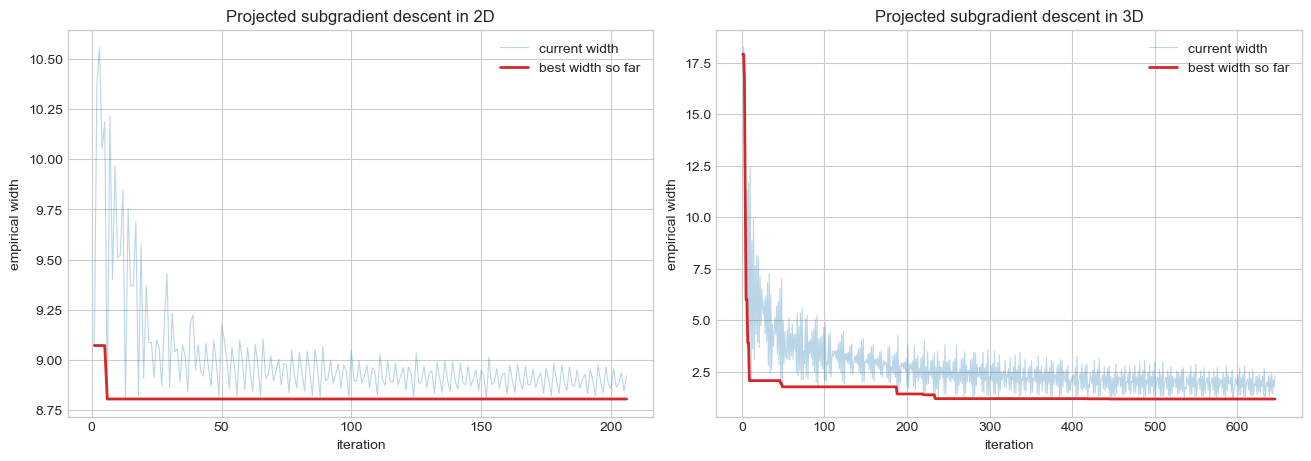

2D minimum width: 8.80492693993552
2D minimizing direction: [0.7341 0.6791]
3D minimum width: 1.1705339207686687
3D minimizing direction: [0.572  0.6177 0.5397]


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

for axis, result, dimension in zip(
    axes,
    (subgradient_2d, subgradient_3d),
    (2, 3),
):
    iteration_numbers = np.arange(1, len(result["width_history"]) + 1)
    axis.plot(
        iteration_numbers,
        result["width_history"],
        color="tab:blue",
        alpha=0.3,
        linewidth=0.8,
        label="current width",
    )
    axis.plot(
        iteration_numbers,
        result["best_width_history"],
        color="tab:red",
        linewidth=2.0,
        label="best width so far",
    )
    axis.set(
        title=f"Projected subgradient descent in {dimension}D",
        xlabel="iteration",
        ylabel="empirical width",
    )
    axis.legend()

plt.show()

print("2D minimum width:", subgradient_2d["minimum_width"])
print("2D minimizing direction:", subgradient_2d["direction"])
print("3D minimum width:", subgradient_3d["minimum_width"])
print("3D minimizing direction:", subgradient_3d["direction"])


## Step-size schedule comparison

The following paired experiment compares the two schedules on the same simulated AR(2) series and the same initial directions. It uses five starts for each embedding dimension, 1,000 iterations, $\eta_0=0.2$, and $\beta=0.99$. Thus the only difference within each pair is

$$\eta_t=\frac{\eta_0}{\sqrt{t+1}} \qquad\text{or}\qquad \eta_t=\eta_0\beta^t.$$


In [6]:
from time import perf_counter
from IPython.display import display

schedule_comparison_dimensions = [2, 3, 5, 10, 25, 100]
schedule_comparison_starts = 5
schedule_comparison_iterations = 1_000
schedule_comparison_initial_step = 0.2
schedule_comparison_geometric_decay = 0.99
schedule_comparison_rng = np.random.default_rng(20260813)
schedule_comparison_rows = []

for dimension in schedule_comparison_dimensions:
    cloud = sliding_window_point_cloud(ar_series, dimension)
    initial_directions = schedule_comparison_rng.normal(
        size=(schedule_comparison_starts, dimension)
    )
    initial_directions /= np.linalg.norm(
        initial_directions, axis=1, keepdims=True
    )

    for start_index, initial_direction in enumerate(initial_directions):
        for step_schedule in ("inverse_sqrt", "geometric"):
            start_time = perf_counter()
            fit = projected_subgradient_empirical_width(
                cloud,
                iterations=schedule_comparison_iterations,
                initial_step=schedule_comparison_initial_step,
                step_schedule=step_schedule,
                geometric_decay=schedule_comparison_geometric_decay,
                patience=schedule_comparison_iterations,
                improvement_tolerance=0.0,
                initial_direction=initial_direction,
                rng=1_000 + dimension + start_index,
            )
            schedule_comparison_rows.append({
                "k": dimension,
                "start": start_index,
                "step_schedule": step_schedule,
                "minimum_width": fit["minimum_width"],
                "seconds": perf_counter() - start_time,
            })

schedule_comparison = pd.DataFrame(schedule_comparison_rows)
paired_widths = schedule_comparison.pivot(
    index=["k", "start"],
    columns="step_schedule",
    values="minimum_width",
)
median_widths = paired_widths.groupby(level="k").median()
schedule_comparison_summary = median_widths.copy()
schedule_comparison_summary["geometric_wins"] = (
    paired_widths["geometric"] < paired_widths["inverse_sqrt"]
).groupby(level="k").sum()
schedule_comparison_summary["relative_improvement_percent"] = (
    100.0
    * (schedule_comparison_summary["inverse_sqrt"]
       - schedule_comparison_summary["geometric"])
    / schedule_comparison_summary["inverse_sqrt"]
)

display(schedule_comparison_summary.round(6))
print(
    "Overall paired wins for the geometric schedule:",
    int((paired_widths["geometric"] < paired_widths["inverse_sqrt"]).sum()),
    "out of",
    len(paired_widths),
)


step_schedule,geometric,inverse_sqrt,geometric_wins,relative_improvement_percent
k,,,,
2,8.803711,8.803923,5,0.002415
3,1.136173,1.157649,5,1.855213
5,1.113758,1.328418,5,16.159066
10,1.153020,1.509784,5,23.630108
25,1.111650,1.809104,5,38.552473
100,1.250909,2.770756,5,54.853158


Overall paired wins for the geometric schedule: 30 out of 30


With seed 20260813, the geometric schedule won all 30 paired trials. The observed median minimum widths were:

| $k$ | Geometric | Inverse square root | Geometric wins |
|---:|---:|---:|---:|
| 2 | 8.803711 | 8.803923 | 5/5 |
| 3 | 1.136173 | 1.157649 | 5/5 |
| 5 | 1.113758 | 1.328418 | 5/5 |
| 10 | 1.153020 | 1.509784 | 5/5 |
| 25 | 1.111650 | 1.809104 | 5/5 |
| 100 | 1.250909 | 2.770756 | 5/5 |

For this fixed iteration budget and tuning, the geometric schedule is clearly better. Its faster decay allows fine local adjustments near a kink, whereas the inverse-square-root step is still approximately $0.0063$ at iteration 1,000 and continues to jump across the nonsmooth minimum. This is an empirical comparison, not a universal guarantee: Theorem 4 is local and its admissible values of $\eta_0$ and $\beta$ depend on the sharpness and initialization constants.


## BIC experiment for AR orders 1 through 10

For each true order, this experiment generates 100 independently parameterized stationary AR processes with uniform innovations, sample size 2,000, and burn-in 1,000. BIC searches candidate orders 0 through 15 so that the experiment at true order 10 is not artificially helped by a search boundary at 10.

BIC accuracy by true AR order
            correct_count  accuracy
true_order                         
1                      95      0.95
2                      92      0.92
3                      91      0.91
4                      96      0.96
5                      83      0.83
6                      86      0.86
7                      87      0.87
8                      92      0.92
9                      82      0.82
10                     87      0.87

Overall: 891/1000

Selected-order distributions
selected_order  0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15
true_order                                                                    
1                4  95   1   0   0   0   0   0   0   0   0   0   0   0   0   0
2                0   8  92   0   0   0   0   0   0   0   0   0   0   0   0   0
3                0   2   5  91   0   1   1   0   0   0   0   0   0   0   0   0
4                0   0   1   3  96   0   0   0   0   0   0   0   0   0   0   0
5              

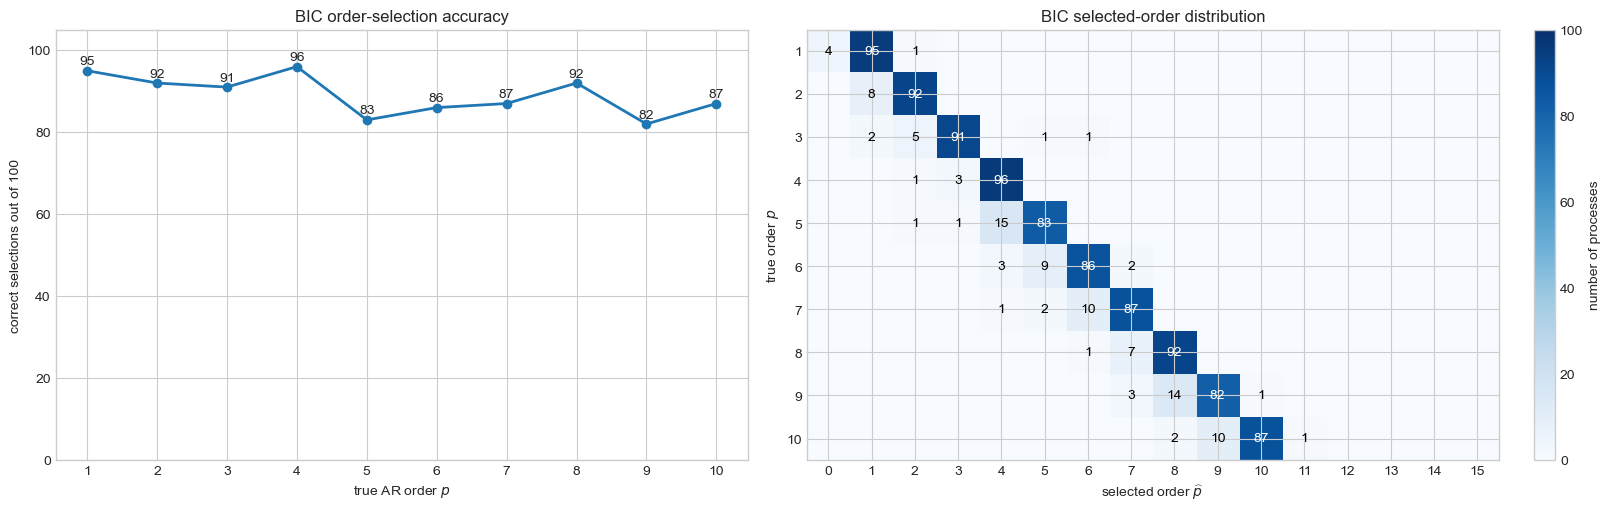

In [7]:
bic_all_order_rows = []
bic_all_order_replications = 100
bic_all_order_sample_size = 2_000
bic_all_order_burnin = 1_000
bic_all_order_maximum_candidate = 15

for true_order in range(1, 11):
    experiment_seed = 20260820 + true_order
    for replication in range(bic_all_order_replications):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=bic_all_order_sample_size,
            burnin=bic_all_order_burnin,
            half_width=1.0,
            rng=process_generator,
        )
        _, selected_order, _ = aic_bic_ar_order(
            series_replication,
            maximum_order=bic_all_order_maximum_candidate,
        )
        bic_all_order_rows.append({
            "true_order": true_order,
            "replication": replication,
            "selected_order": selected_order,
            "correct": selected_order == true_order,
            "absolute_final_coefficient": abs(phi_replication[-1]),
        })

bic_all_order_results = pd.DataFrame(bic_all_order_rows)
bic_all_order_summary = (
    bic_all_order_results
    .groupby("true_order")["correct"]
    .agg(correct_count="sum", accuracy="mean")
)
bic_all_order_distribution = (
    bic_all_order_results
    .groupby(["true_order", "selected_order"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=np.arange(16), fill_value=0)
)
print("BIC accuracy by true AR order")
print(bic_all_order_summary.to_string())
print(
    f"\nOverall: {bic_all_order_summary['correct_count'].sum()}/"
    f"{10 * bic_all_order_replications}"
)
print("\nSelected-order distributions")
print(bic_all_order_distribution.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
axes[0].plot(
    bic_all_order_summary.index,
    bic_all_order_summary["correct_count"],
    marker="o",
    linewidth=2,
    color="tab:blue",
)
for order, count in bic_all_order_summary["correct_count"].items():
    axes[0].text(order, count + 1.5, str(count), ha="center")
axes[0].set(
    title="BIC order-selection accuracy",
    xlabel=r"true AR order $p$",
    ylabel="correct selections out of 100",
    xticks=np.arange(1, 11),
    ylim=(0, 105),
)

confusion_values = bic_all_order_distribution.to_numpy()
image = axes[1].imshow(
    confusion_values,
    cmap="Blues",
    vmin=0,
    vmax=100,
    aspect="auto",
)
for row in range(confusion_values.shape[0]):
    for column in range(confusion_values.shape[1]):
        if confusion_values[row, column] > 0:
            axes[1].text(
                column, row, str(confusion_values[row, column]),
                ha="center", va="center",
                color=(
                    "white" if confusion_values[row, column] > 50
                    else "black"
                ),
            )
axes[1].set(
    title="BIC selected-order distribution",
    xlabel=r"selected order $\widehat p$",
    ylabel=r"true order $p$",
    xticks=np.arange(16),
    yticks=np.arange(10),
    yticklabels=np.arange(1, 11),
)
fig.colorbar(image, ax=axes[1], label="number of processes")
plt.show()

## Ten empirical minimum-width curves for uniform AR(3) processes

Here $T=2{,}000$ denotes the number of retained observations in each independently generated process; an additional 1,000 observations are discarded as burn-in. Each process has an independently generated stationary AR(3) coefficient vector and independent $\operatorname{Uniform}[-1,1]$ innovations. The curves use three starts, 500 batched Riemannian subgradient iterations, and the geometric step sequence $\eta_t=0.2(0.99)^t$.


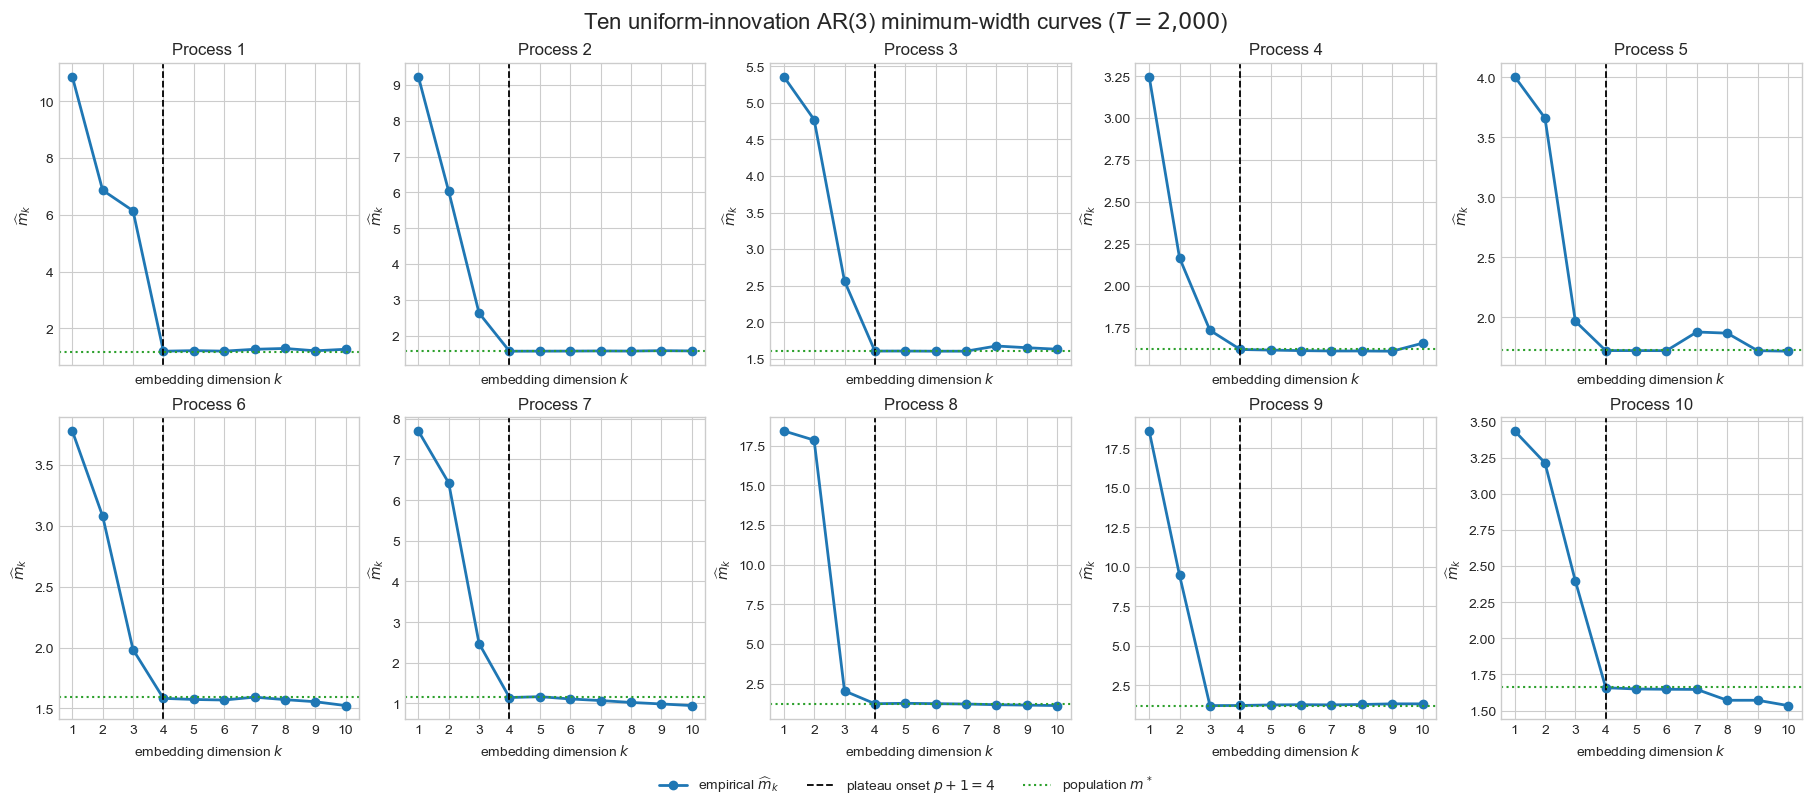

T = 2000 retained observations per process
AR coefficient vectors:
[[ 0.7649  0.722  -0.8923]
 [ 0.4573 -0.0749 -0.647 ]
 [ 0.0805 -0.5619  0.4686]
 [-0.6587 -0.2678 -0.0772]
 [-0.2355 -0.4942  0.2005]
 [-0.4577 -0.5735 -0.198 ]
 [ 0.8322 -1.0168  0.5372]
 [ 0.6702 -1.0886  0.3894]
 [ 1.2172 -0.7063 -0.1812]
 [ 0.3879 -0.4416  0.3206]]


In [8]:
ar3_curve_process_count = 10
ar3_curve_sample_size_T = 2_000
ar3_curve_burnin = 1_000
ar3_curve_k_values = np.arange(1, 11)
ar3_curve_seed = 20260814
ar3_curve_rows = []
ar3_curve_coefficients = []

fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for replication, axis in enumerate(axes.flat):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar3_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        3, rng=process_generator
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar3_curve_sample_size_T,
        burnin=ar3_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar3_curve_k_values,
        seed=ar3_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    population_plateau = 2.0 / np.linalg.norm(
        np.concatenate(([1.0], -phi_replication))
    )
    ar3_curve_coefficients.append(phi_replication)
    for k, width in zip(ar3_curve_k_values, minimized_widths):
        ar3_curve_rows.append({
            "process": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })

    axis.plot(
        ar3_curve_k_values, minimized_widths,
        marker="o", linewidth=2.0, color="tab:blue",
        label=r"empirical $\widehat m_k$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.3,
        label=r"plateau onset $p+1=4$",
    )
    axis.axhline(
        population_plateau, color="tab:green", linestyle=":",
        linewidth=1.5, label=r"population $m^*$",
    )
    axis.set_title(f"Process {replication + 1}")
    axis.set_xticks(ar3_curve_k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=3, frameon=False
)
fig.suptitle(
    r"Ten uniform-innovation AR(3) minimum-width curves ($T=2{,}000$)",
    fontsize=16,
)
ar3_curve_results = pd.DataFrame(ar3_curve_rows)
ar3_curve_figure_path = (
    MINIMUM_WIDTH_IMAGES_DIR / "ar3_ten_minimum_width_curves.png"
)
fig.savefig(ar3_curve_figure_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"T = {ar3_curve_sample_size_T} retained observations per process")
print("AR coefficient vectors:")
print(np.asarray(ar3_curve_coefficients))


## Constrained horizontal-tail L-method on the ten AR(3) curves

This is a tailored L-method: for every candidate $q$, it fits the continuous shape $f_q(k)=c+s(q-k)_+$ with $s\geq0$ by least absolute deviations. Thus the segment from $q$ onward is forced to be horizontal. The candidate with the smallest absolute residual sum is selected, with $\widehat p=\widehat q-1$. No smoothing or threshold is used. The same curves with $T=2{,}000$ and $K=10$ are reused.


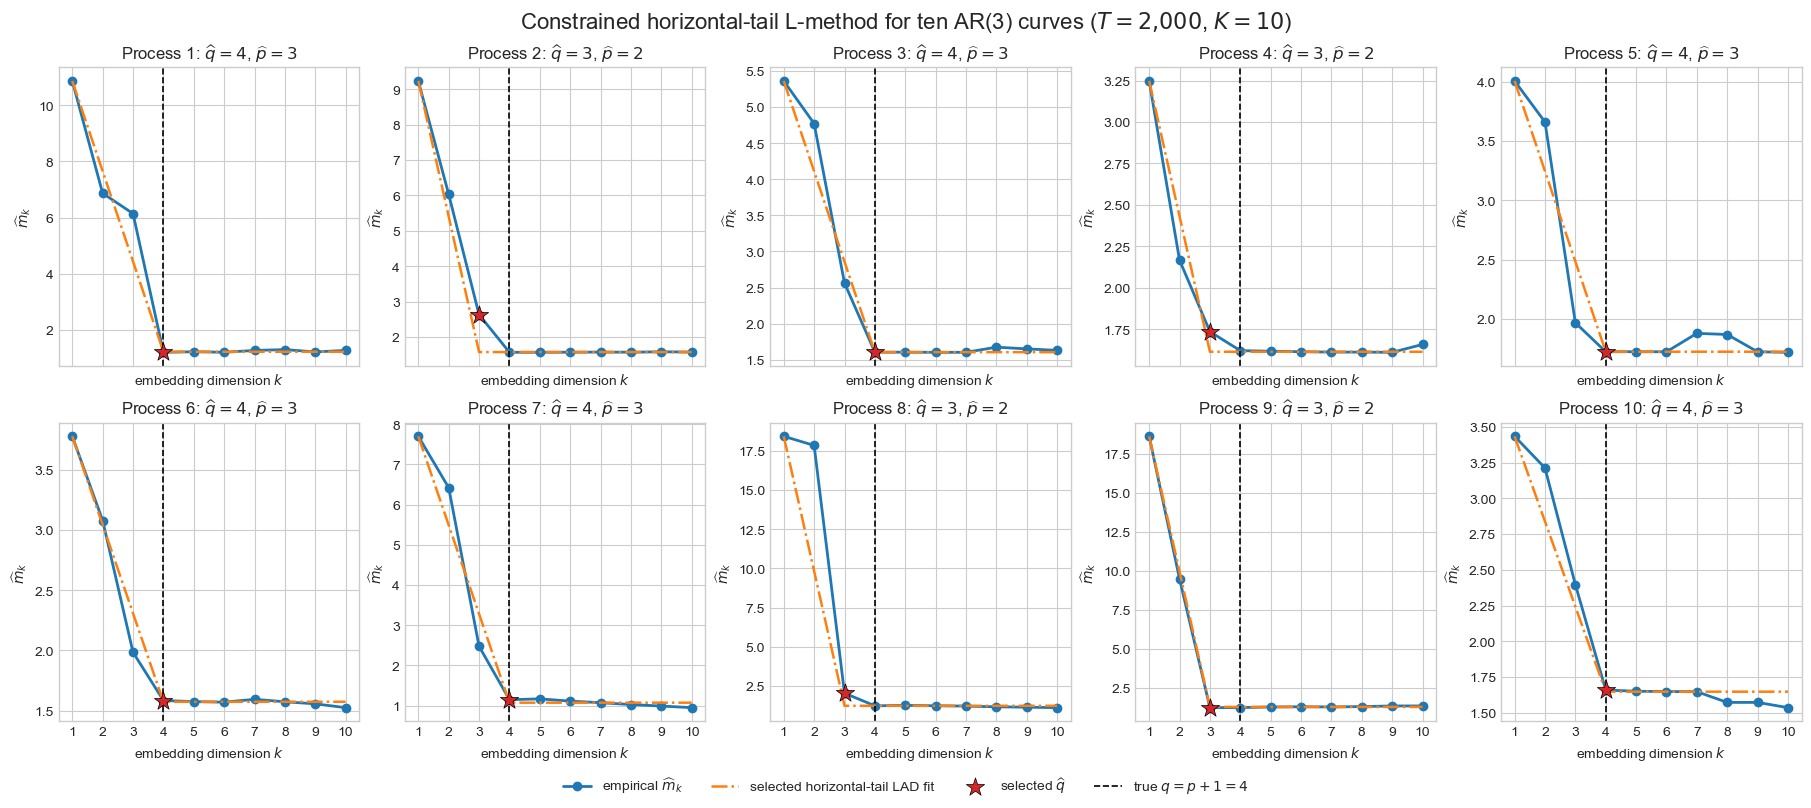

T = 2000 retained observations per process; K = 10
 process  selected_q  selected_order  correct_order  absolute_residual_score
       1           4               3           True                 2.709376
       2           3               2          False                 1.712107
       3           4               3           True                 1.101026
       4           3               2          False                 0.447166
       5           4               3           True                 1.238347
       6           4               3           True                 0.461437
       7           4               3           True                 2.200130
       8           3               2          False                 9.135515
       9           3               2          False                 0.719910
      10           4               3           True                 0.806122
Correct AR(3) selections: 6/10


In [9]:
horizontal_tail_lad_rows = []
fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    k_values = process_results["k"].to_numpy()
    widths = process_results["minimum_width"].to_numpy()
    selection = horizontal_tail_lad_selector(k_values, widths)
    selected_q = selection["selected_q"]
    selected_width = widths[np.flatnonzero(k_values == selected_q)[0]]
    horizontal_tail_lad_rows.append({
        "process": process,
        "selected_q": selected_q,
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 3,
        "absolute_residual_score": selection["score"],
    })

    axis.plot(
        k_values, widths, marker="o", linewidth=2.0, color="tab:blue",
        label=r"empirical $\widehat m_k$",
    )
    axis.plot(
        k_values, selection["fitted_values"], linestyle="-.",
        linewidth=1.8, color="tab:orange",
        label="selected horizontal-tail LAD fit",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.2,
        label=r"true $q=p+1=4$",
    )
    axis.set_title(
        rf"Process {process}: $\widehat q={selected_q}$, "
        rf"$\widehat p={selection['selected_order']}$"
    )
    axis.set_xticks(k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
fig.suptitle(
    r"Constrained horizontal-tail L-method for ten AR(3) curves "
    r"($T=2{,}000$, $K=10$)",
    fontsize=16,
)
horizontal_tail_lad_results = pd.DataFrame(horizontal_tail_lad_rows)
horizontal_tail_lad_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar3" / "ar3_ten_horizontal_tail_lad.png"
)
fig.savefig(
    horizontal_tail_lad_figure_path, dpi=180, bbox_inches="tight"
)
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(horizontal_tail_lad_results.to_string(index=False))
print(
    f"Correct AR(3) selections: "
    f"{int(horizontal_tail_lad_results['correct_order'].sum())}/10"
)


## Constrained horizontal-tail L-method with $T=5{,}000$

This repeats the preceding ten-process experiment with the same AR(3) coefficient vectors, random seeds, burn-in of 1,000, $K=10$, and optimization settings. Only the retained sample size changes from $T=2{,}000$ to $T=5{,}000$.


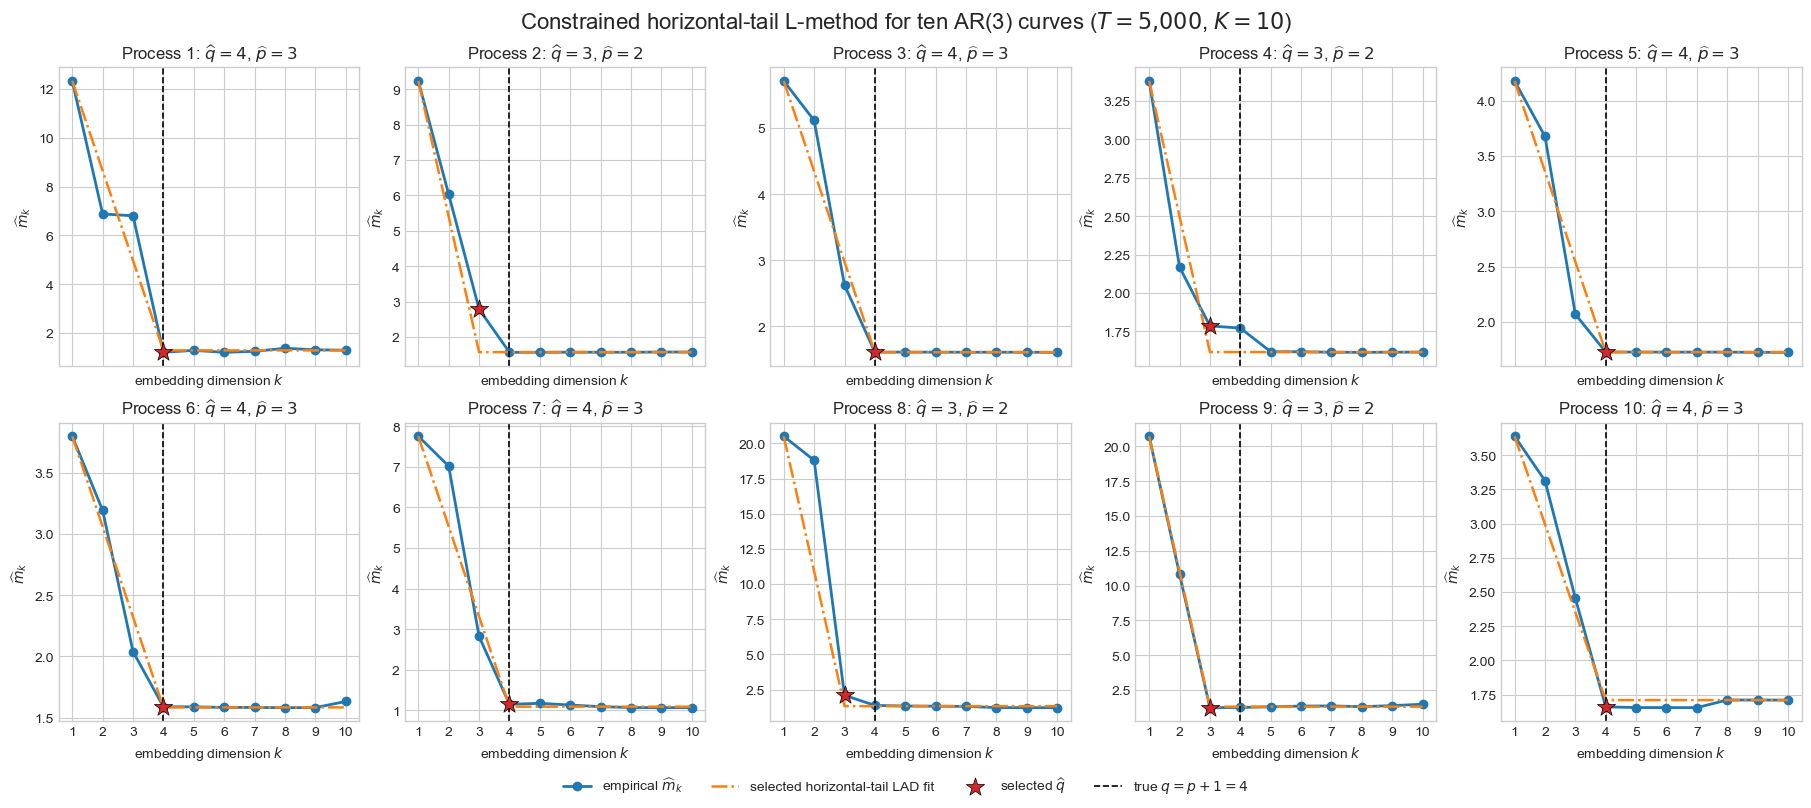

T = 5000 retained observations per process; burn-in = 1000; K = 10
 process  selected_order_T2000  selected_order_T5000
       1                     3                     3
       2                     2                     2
       3                     3                     3
       4                     2                     2
       5                     3                     3
       6                     3                     3
       7                     3                     3
       8                     2                     2
       9                     2                     2
      10                     3                     3
Correct AR(3) selections at T=5000: 6/10


In [10]:
ar3_lad_T5000_sample_size = 5_000
ar3_lad_T5000_rows = []
ar3_lad_T5000_curve_rows = []
ar3_lad_T5000_coefficients = []

fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for replication, axis in enumerate(axes.flat):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar3_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(3, rng=process_generator)
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar3_lad_T5000_sample_size,
        burnin=ar3_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar3_curve_k_values,
        seed=ar3_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar3_curve_k_values, minimized_widths
    )
    selected_q = selection["selected_q"]
    selected_width = minimized_widths[
        np.flatnonzero(ar3_curve_k_values == selected_q)[0]
    ]
    ar3_lad_T5000_coefficients.append(phi_replication)
    ar3_lad_T5000_rows.append({
        "process": replication + 1,
        "selected_q": selected_q,
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 3,
        "absolute_residual_score": selection["score"],
    })
    for k, width in zip(ar3_curve_k_values, minimized_widths):
        ar3_lad_T5000_curve_rows.append({
            "process": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })

    axis.plot(
        ar3_curve_k_values, minimized_widths, marker="o", linewidth=2.0,
        color="tab:blue", label=r"empirical $\widehat m_k$",
    )
    axis.plot(
        ar3_curve_k_values, selection["fitted_values"], linestyle="-.",
        linewidth=1.8, color="tab:orange",
        label="selected horizontal-tail LAD fit",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"selected $\widehat q$",
    )
    axis.axvline(
        4, color="black", linestyle="--", linewidth=1.2,
        label=r"true $q=p+1=4$",
    )
    axis.set_title(
        rf"Process {replication + 1}: $\widehat q={selected_q}$, "
        rf"$\widehat p={selection['selected_order']}$"
    )
    axis.set_xticks(ar3_curve_k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
fig.suptitle(
    r"Constrained horizontal-tail L-method for ten AR(3) curves "
    r"($T=5{,}000$, $K=10$)",
    fontsize=16,
)
ar3_lad_T5000_results = pd.DataFrame(ar3_lad_T5000_rows)
ar3_lad_T5000_curve_results = pd.DataFrame(ar3_lad_T5000_curve_rows)
ar3_lad_T5000_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar3" / "ar3_ten_horizontal_tail_lad_T5000.png"
)
fig.savefig(ar3_lad_T5000_figure_path, dpi=180, bbox_inches="tight")
plt.show()

ar3_lad_sample_size_comparison = horizontal_tail_lad_results[[
    "process", "selected_order"
]].rename(columns={"selected_order": "selected_order_T2000"}).merge(
    ar3_lad_T5000_results[["process", "selected_order"]].rename(
        columns={"selected_order": "selected_order_T5000"}
    ),
    on="process",
)
print("T = 5000 retained observations per process; burn-in = 1000; K = 10")
print(ar3_lad_sample_size_comparison.to_string(index=False))
print(
    f"Correct AR(3) selections at T=5000: "
    f"{int(ar3_lad_T5000_results['correct_order'].sum())}/10"
)


## Adjacent-drop curves for the ten AR(3) processes at $T=2{,}000$

For each of the original ten curves, calculate $\widehat\Delta_k=\widehat m_k-\widehat m_{k+1}$ for $k=1,\ldots,9$. Proposition 3 and monotonicity identify $p=3$ as the final population index with a strictly positive drop; the dashed line therefore marks $k=p=3$.


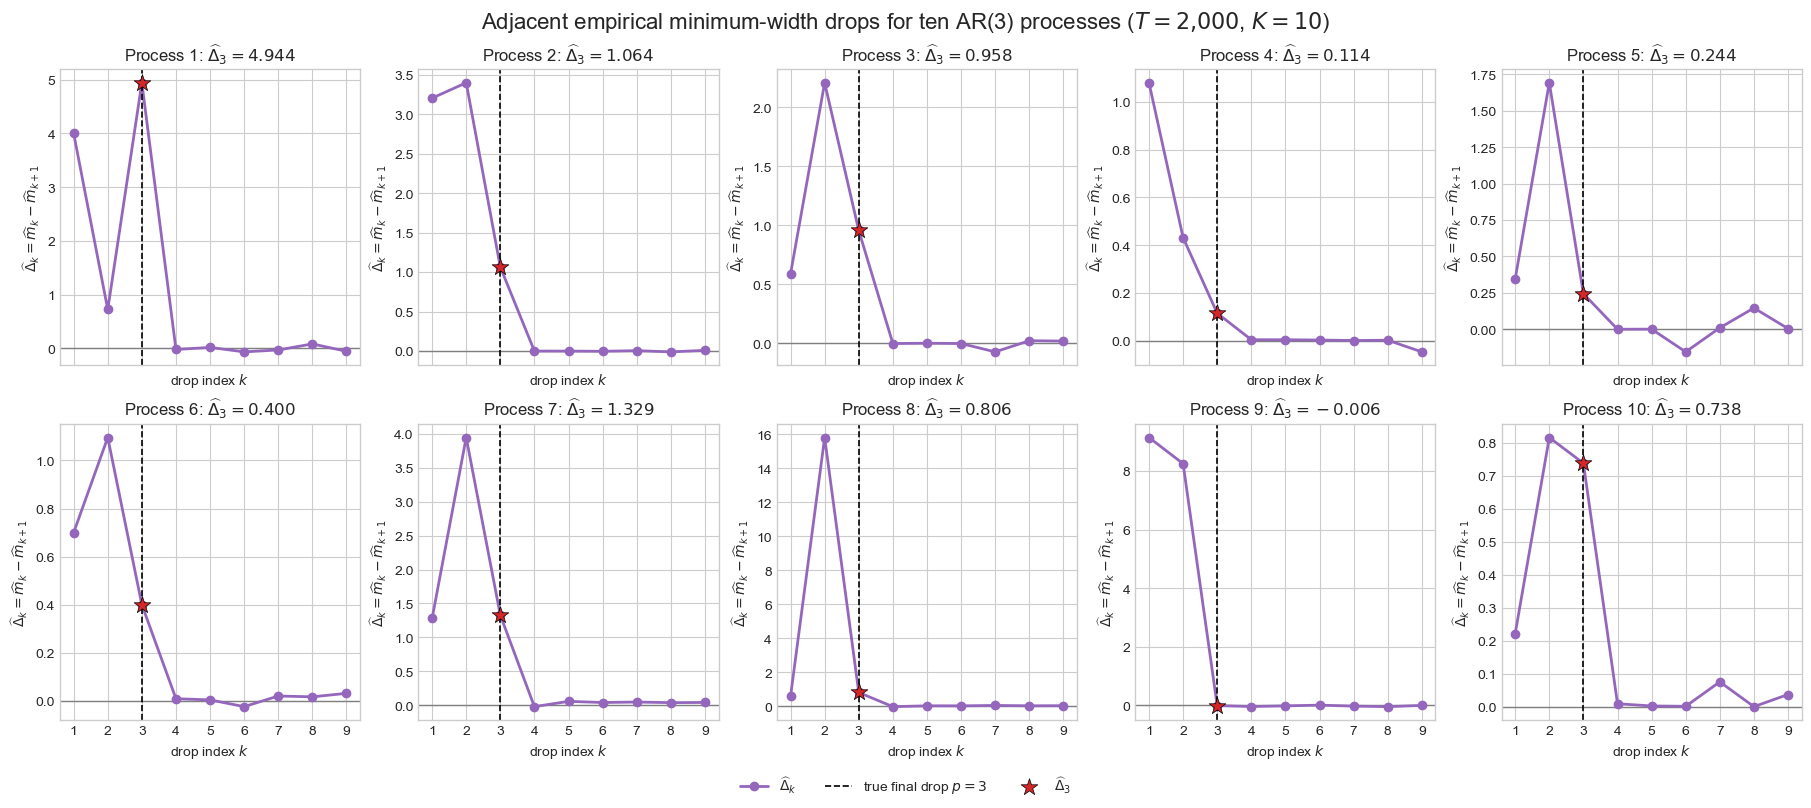

T = 2000 retained observations per process; K = 10
 process  k  adjacent_drop
       1  1       4.003057
       1  2       0.724054
       1  3       4.943913
       1  4      -0.020183
       1  5       0.017782
       1  6      -0.065028
       1  7      -0.029693
       1  8       0.083012
       1  9      -0.054331
       2  1       3.206229
       2  2       3.401074
       2  3       1.064418
       2  4      -0.001343
       2  5      -0.001735
       2  6      -0.004115
       2  7       0.003749
       2  8      -0.011499
       2  9       0.007560
       3  1       0.590245
       3  2       2.209107
       3  3       0.957636
       3  4      -0.000334
       3  5       0.002238
       3  6      -0.000231
       3  7      -0.071000
       3  8       0.023471
       3  9       0.020480
       4  1       1.080952
       4  2       0.431241
       4  3       0.114464
       4  4       0.003456
       4  5       0.003254
       4  6       0.002101
       4  7       0.000005
    

In [11]:
ar3_delta_rows = []
fig, axes = plt.subplots(
    2, 5, figsize=(18, 8), sharex=True, constrained_layout=True
)
for process, axis in zip(range(1, 11), axes.flat):
    process_results = ar3_curve_results.loc[
        ar3_curve_results["process"] == process
    ].sort_values("k")
    widths = process_results["minimum_width"].to_numpy()
    drop_indices = process_results["k"].to_numpy()[:-1]
    adjacent_drops = widths[:-1] - widths[1:]
    for k, drop in zip(drop_indices, adjacent_drops):
        ar3_delta_rows.append({
            "process": process,
            "k": int(k),
            "adjacent_drop": float(drop),
        })

    axis.axhline(0.0, color="tab:gray", linewidth=1.0)
    axis.plot(
        drop_indices, adjacent_drops, marker="o", linewidth=2.0,
        color="tab:purple", label=r"$\widehat\Delta_k$",
    )
    axis.axvline(
        3, color="black", linestyle="--", linewidth=1.2,
        label=r"true final drop $p=3$",
    )
    axis.scatter(
        [3], [adjacent_drops[2]], marker="*", s=160,
        color="tab:red", edgecolor="black", linewidth=0.5, zorder=5,
        label=r"$\widehat\Delta_3$",
    )
    axis.set_title(
        rf"Process {process}: $\widehat\Delta_3={adjacent_drops[2]:.3f}$"
    )
    axis.set_xticks(drop_indices)
    axis.set_xlabel(r"drop index $k$")
    axis.set_ylabel(r"$\widehat\Delta_k=\widehat m_k-\widehat m_{k+1}$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle(
    r"Adjacent empirical minimum-width drops for ten AR(3) processes "
    r"($T=2{,}000$, $K=10$)",
    fontsize=16,
)
ar3_delta_results = pd.DataFrame(ar3_delta_rows)
ar3_delta_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar3" / "ar3_ten_adjacent_drops_T2000.png"
)
fig.savefig(ar3_delta_figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(ar3_delta_results.to_string(index=False))


## Specialized linear horizontal-tail L-method on ten AR(1) processes

Ten independently generated stationary AR(1) processes with $\operatorname{Uniform}[-1,1]$ innovations are simulated using $T=2{,}000$ retained observations, burn-in 1,000, and embedding dimensions $k=1,\ldots,10$. Minimum widths use three optimizer starts, 500 projected-subgradient iterations, and $\eta_t=0.2(0.99)^t$. For every curve, the selector fits $f_q(k)=c+s(q-k)_+$ with $s\geq0$ by least absolute deviations. The correct plateau onset is $q_0=p+1=2$.


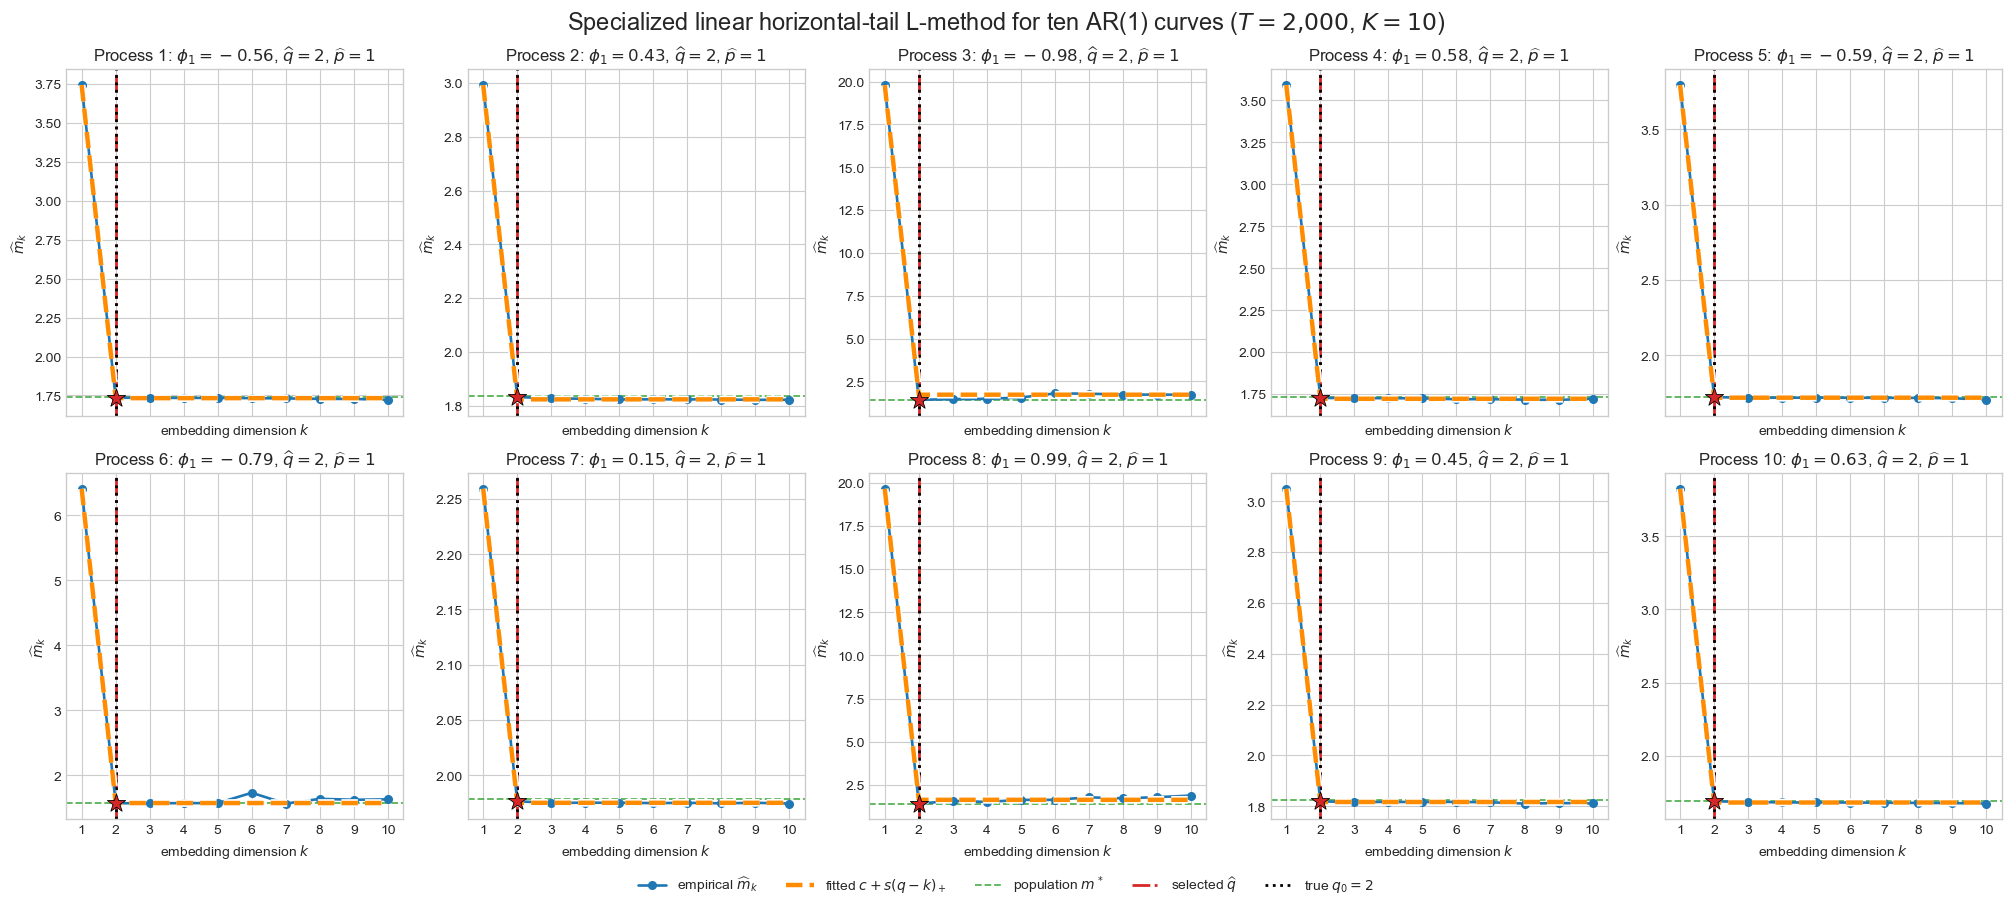

T = 2000 retained observations per process; K = 10
 process     phi_1  selected_q  selected_order  correct_order  absolute_residual_score
       1 -0.563498           2               1           True                 0.030068
       2  0.431757           2               1           True                 0.019047
       3 -0.984023           2               1           True                 1.105435
       4  0.575758           2               1           True                 0.031119
       5 -0.586518           2               1           True                 0.023772
       6 -0.787251           2               1           True                 0.345183
       7  0.148844           2               1           True                 0.002920
       8  0.990740           2               1           True                 1.035222
       9  0.451668           2               1           True                 0.020158
      10  0.629104           2               1           True                 0

In [12]:
ar1_curve_process_count = 10
ar1_curve_sample_size_T = 2_000
ar1_curve_burnin = 1_000
ar1_curve_k_values = np.arange(1, 11)
ar1_curve_seed = 20260813
ar1_specialized_l_rows = []
ar1_curve_rows = []

fig, axes = plt.subplots(
    2, 5, figsize=(20, 9), sharex=True, constrained_layout=True
)
for replication, axis in enumerate(axes.flat):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar1_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        1, rng=process_generator
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar1_curve_sample_size_T,
        burnin=ar1_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar1_curve_k_values,
        seed=ar1_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar1_curve_k_values, minimized_widths
    )
    selected_q = selection["selected_q"]
    selected_order = selection["selected_order"]
    selected_width = minimized_widths[
        np.flatnonzero(ar1_curve_k_values == selected_q)[0]
    ]
    population_plateau = 2.0 / np.linalg.norm(
        np.concatenate(([1.0], -phi_replication))
    )
    ar1_specialized_l_rows.append({
        "process": replication + 1,
        "phi_1": float(phi_replication[0]),
        "selected_q": selected_q,
        "selected_order": selected_order,
        "correct_order": selected_order == 1,
        "absolute_residual_score": selection["score"],
    })
    for k, width in zip(ar1_curve_k_values, minimized_widths):
        ar1_curve_rows.append({
            "process": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })

    axis.plot(
        ar1_curve_k_values, minimized_widths, marker="o",
        markersize=5.5, linewidth=1.9, color="tab:blue", zorder=3,
        label=r"empirical $\widehat m_k$",
    )
    fitted_line, = axis.plot(
        ar1_curve_k_values, selection["fitted_values"],
        linestyle="--", linewidth=3.2, color="darkorange", zorder=4,
        label=r"fitted $c+s(q-k)_+$",
    )
    fitted_line.set_path_effects([
        path_effects.Stroke(linewidth=5.6, foreground="white"),
        path_effects.Normal(),
    ])
    axis.axhline(
        population_plateau, color="tab:green", linestyle="--",
        linewidth=1.3, alpha=0.8, label=r"population $m^*$",
    )
    axis.axvline(
        selected_q, color="tab:red", linestyle="-.", linewidth=2.0,
        zorder=2, label=r"selected $\widehat q$",
    )
    axis.axvline(
        2, color="black", linestyle=":", linewidth=2.0, zorder=2,
        label=r"true $q_0=2$",
    )
    axis.scatter(
        [selected_q], [selected_width], marker="*", s=190,
        color="tab:red", edgecolor="black", linewidth=0.6, zorder=6,
    )
    axis.set_title(
        rf"Process {replication + 1}: $\phi_1={phi_replication[0]:.2f}$, "
        rf"$\widehat q={selected_q}$, $\widehat p={selected_order}$"
    )
    axis.set_xticks(ar1_curve_k_values)
    axis.set_xlabel(r"embedding dimension $k$")
    axis.set_ylabel(r"$\widehat m_k$")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=5, frameon=False
)
fig.suptitle(
    r"Specialized linear horizontal-tail L-method for ten AR(1) curves "
    r"($T=2{,}000$, $K=10$)",
    fontsize=17,
)
ar1_specialized_l_results = pd.DataFrame(ar1_specialized_l_rows)
ar1_curve_results = pd.DataFrame(ar1_curve_rows)
ar1_specialized_l_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar1" / "ar1_ten_specialized_linear_l_T2000.png"
)
fig.savefig(
    ar1_specialized_l_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("T = 2000 retained observations per process; K = 10")
print(ar1_specialized_l_results.to_string(index=False))
print(
    f"Correct AR(1) selections: "
    f"{int(ar1_specialized_l_results['correct_order'].sum())}/10"
)


**Result.** The specialized linear horizontal-tail method selects $\widehat q=2$ and therefore $\widehat p=1$ in all ten processes. This includes the comparatively difficult processes 3 and 8, whose coefficients are close to the stationarity boundary at $-0.984$ and $0.991$. Thus the inability to select AR(1) is specific to the original disjoint two-line L-method; the specialized continuous model has no such guardrail because the candidate $q=2$ is well defined. The 10/10 outcome is encouraging but is only a small visual experiment, not an independently calibrated selection-rate estimate.


## Fifty-process AR(1) experiment for the specialized linear L-method

The preceding visual experiment is extended to 50 independently generated stationary AR(1) processes. All settings remain fixed: $T=2{,}000$, burn-in 1,000, $K=10$, $\operatorname{Uniform}[-1,1]$ innovations, three optimizer starts, 500 projected-subgradient iterations, and geometric steps $\eta_t=0.2(0.99)^t$. Replications 1--10 use the same seeds as the preceding figure and replications 11--50 are new.


Completed 10/50 AR(1) processes
Completed 20/50 AR(1) processes
Completed 30/50 AR(1) processes
Completed 40/50 AR(1) processes
Completed 50/50 AR(1) processes


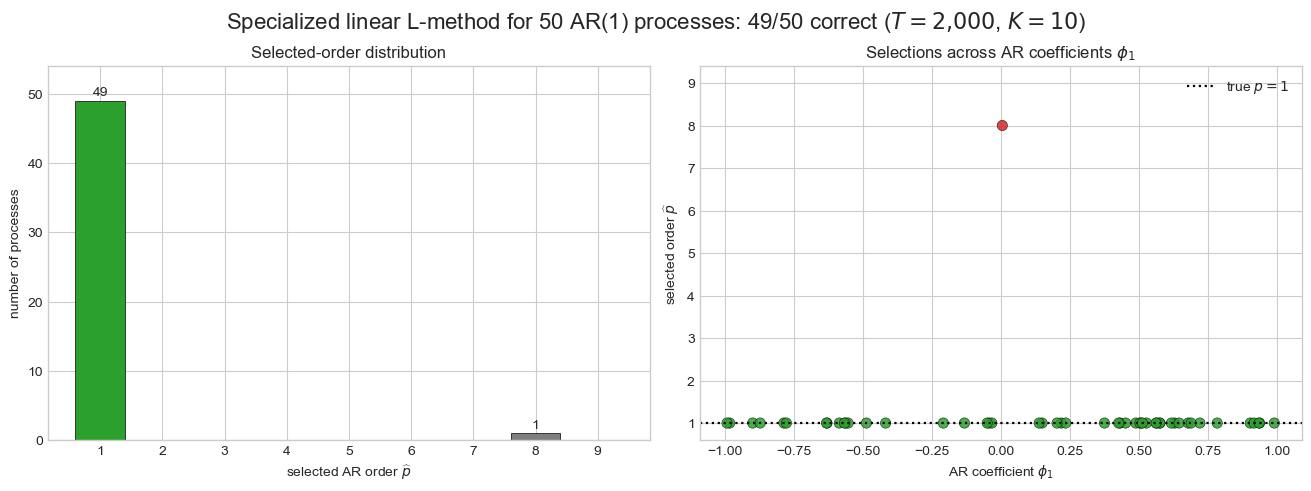

Selected-order counts
selected_order
1    49
2     0
3     0
4     0
5     0
6     0
7     0
8     1
9     0
Correct AR(1) selections: 49/50
Incorrect replications
 replication    phi_1  selected_q  selected_order  correct_order  absolute_residual_score  population_gap
          27 0.004569           9               8          False                 0.007572        0.000021


In [13]:
ar1_fifty_process_count = 50
ar1_fifty_rows = []
ar1_fifty_width_rows = []
for replication in range(ar1_fifty_process_count):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar1_curve_seed, replication, 0
    ]))
    phi_replication = jones_ar_coefficients(
        1, rng=process_generator
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=ar1_curve_sample_size_T,
        burnin=ar1_curve_burnin,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar1_curve_k_values,
        seed=ar1_curve_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar1_curve_k_values, minimized_widths
    )
    ar1_fifty_rows.append({
        "replication": replication + 1,
        "phi_1": float(phi_replication[0]),
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 1,
        "absolute_residual_score": selection["score"],
        "population_gap": float(
            2.0 - 2.0 / np.sqrt(1.0 + phi_replication[0] ** 2)
        ),
    })
    for k, width in zip(ar1_curve_k_values, minimized_widths):
        ar1_fifty_width_rows.append({
            "replication": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })
    if (replication + 1) % 10 == 0:
        print(f"Completed {replication + 1}/50 AR(1) processes")

ar1_fifty_results = pd.DataFrame(ar1_fifty_rows)
ar1_fifty_width_results = pd.DataFrame(ar1_fifty_width_rows)
ar1_fifty_order_counts = (
    ar1_fifty_results["selected_order"].value_counts()
    .reindex(np.arange(1, 10), fill_value=0).sort_index()
)
ar1_fifty_correct_count = int(ar1_fifty_results["correct_order"].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
bar_colors = [
    "tab:green" if order == 1 else "tab:gray"
    for order in ar1_fifty_order_counts.index
]
axes[0].bar(
    ar1_fifty_order_counts.index, ar1_fifty_order_counts.values,
    color=bar_colors, edgecolor="black", linewidth=0.5,
)
for order, count in ar1_fifty_order_counts.items():
    if count:
        axes[0].text(order, count + 0.7, str(count), ha="center")
axes[0].set(
    title="Selected-order distribution",
    xlabel=r"selected AR order $\widehat p$",
    ylabel="number of processes",
    xticks=ar1_fifty_order_counts.index,
    ylim=(0, max(ar1_fifty_order_counts.max() + 5, 10)),
)

point_colors = np.where(
    ar1_fifty_results["correct_order"], "tab:green", "tab:red"
)
axes[1].scatter(
    ar1_fifty_results["phi_1"],
    ar1_fifty_results["selected_order"],
    c=point_colors, s=55, edgecolor="black", linewidth=0.4, alpha=0.85,
)
axes[1].axhline(
    1, color="black", linestyle=":", linewidth=1.6,
    label=r"true $p=1$",
)
axes[1].set(
    title=r"Selections across AR coefficients $\phi_1$",
    xlabel=r"AR coefficient $\phi_1$",
    ylabel=r"selected order $\widehat p$",
    yticks=np.arange(1, 10), ylim=(0.6, 9.4),
)
axes[1].legend(frameon=False)
fig.suptitle(
    rf"Specialized linear L-method for 50 AR(1) processes: "
    rf"{ar1_fifty_correct_count}/50 correct "
    rf"($T=2{{,}}000$, $K=10$)",
    fontsize=16,
)
ar1_fifty_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar1" / "ar1_specialized_linear_l_50_T2000.png"
)
fig.savefig(ar1_fifty_figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Selected-order counts")
print(ar1_fifty_order_counts.to_string())
print(f"Correct AR(1) selections: {ar1_fifty_correct_count}/50")
if ar1_fifty_correct_count < ar1_fifty_process_count:
    print("Incorrect replications")
    print(ar1_fifty_results.loc[
        ~ar1_fifty_results["correct_order"]
    ].to_string(index=False))


**Result.** The specialized linear horizontal-tail L-method selects the correct AR(1) order in 49 of 50 processes. The sole failure is replication 27, where $\phi_1=0.004569$ and the method selects $\widehat q=9$, hence $\widehat p=8$. This coefficient is extremely close to zero, so the nominal AR(1) process is practically white noise. Its population separation between the first width and the plateau is only $2-2/\sqrt{1+\phi_1^2}\approx2.1\times10^{-5}$, which is far smaller than the empirical width fluctuations at $T=2{,}000$. The failure therefore reflects a near-nonidentifiable order boundary rather than the original L-method's AR(1) guardrail. Pointwise consistency for a fixed nonzero coefficient would not imply uniform reliability when $\phi_1$ is allowed to approach zero.


## Fifty-process AR(2) experiment for the specialized linear L-method

Fifty independently generated stationary AR(2) processes with $\operatorname{Uniform}[-1,1]$ innovations are evaluated using the unregularized specialized linear model $f_q(k)=c+s(q-k)_+$. The design matches the AR(1) experiment: $T=2{,}000$, burn-in 1,000, $K=10$, three optimizer starts, 500 projected-subgradient iterations, and $\eta_t=0.2(0.99)^t$. The correct plateau onset is now $q_0=p+1=3$.


Completed 10/50 AR(2) processes
Completed 20/50 AR(2) processes
Completed 30/50 AR(2) processes
Completed 40/50 AR(2) processes
Completed 50/50 AR(2) processes


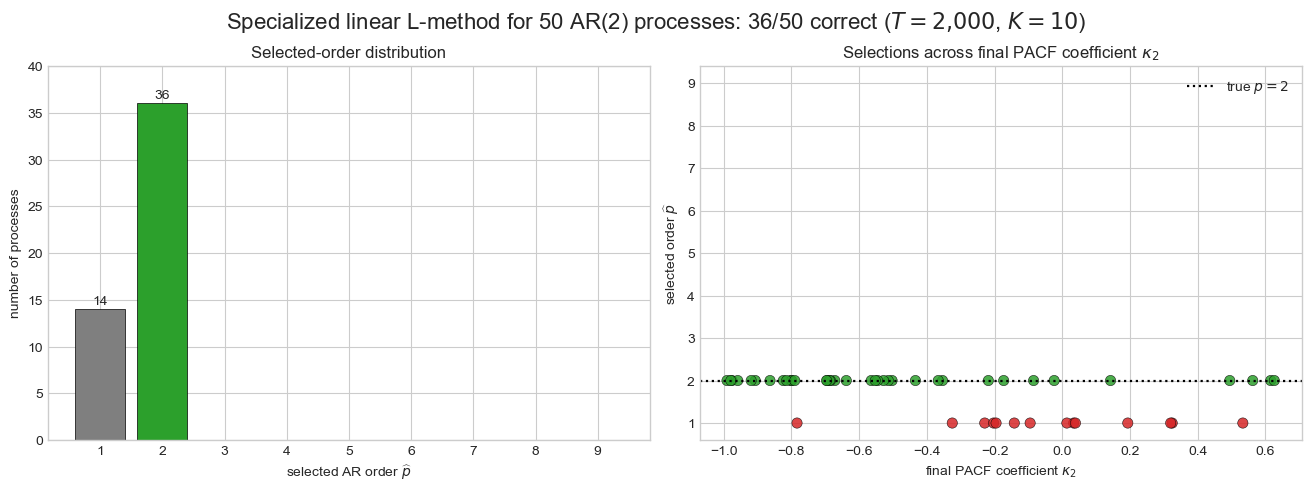

Selected-order counts
selected_order
1    14
2    36
3     0
4     0
5     0
6     0
7     0
8     0
9     0
Correct AR(2) selections: 36/50
Incorrect replications
 replication     phi_1     phi_2    pacf_2  selected_q  selected_order  absolute_residual_score
           1  0.592317  0.193434  0.193434           2               1                 0.508918
          12  1.065318 -0.228971 -0.228971           2               1                 0.706452
          21  0.264591  0.033658  0.033658           2               1                 0.058712
          22  0.447423  0.533239  0.533239           2               1                 1.349830
          24  0.081404  0.013580  0.013580           2               1                 0.048075
          28 -0.732536 -0.141644 -0.141644           2               1                 0.355687
          31 -0.598123  0.324582  0.324582           2               1                 0.896260
          34  0.370947  0.320131  0.320131           2              

In [14]:
ar2_fifty_process_count = 50
ar2_fifty_seed = 20260814
ar2_fifty_k_values = np.arange(1, 11)
ar2_fifty_rows = []
ar2_fifty_width_rows = []
for replication in range(ar2_fifty_process_count):
    process_generator = np.random.default_rng(np.random.SeedSequence([
        ar2_fifty_seed, replication, 0
    ]))
    phi_replication, pacf_replication = jones_ar_coefficients(
        2, rng=process_generator, return_pacf=True
    )
    series_replication = simulate_uniform_ar(
        phi_replication,
        sample_size=2_000,
        burnin=1_000,
        half_width=1.0,
        rng=process_generator,
    )
    _, minimized_widths, _ = batched_geometric_width_curves(
        series_replication,
        ar2_fifty_k_values,
        seed=ar2_fifty_seed,
        replication=replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
    )
    selection = horizontal_tail_lad_selector(
        ar2_fifty_k_values, minimized_widths
    )
    ar2_fifty_rows.append({
        "replication": replication + 1,
        "phi_1": float(phi_replication[0]),
        "phi_2": float(phi_replication[1]),
        "pacf_2": float(pacf_replication[1]),
        "selected_q": selection["selected_q"],
        "selected_order": selection["selected_order"],
        "correct_order": selection["selected_order"] == 2,
        "absolute_residual_score": selection["score"],
    })
    for k, width in zip(ar2_fifty_k_values, minimized_widths):
        ar2_fifty_width_rows.append({
            "replication": replication + 1,
            "k": int(k),
            "minimum_width": float(width),
        })
    if (replication + 1) % 10 == 0:
        print(f"Completed {replication + 1}/50 AR(2) processes")

ar2_fifty_results = pd.DataFrame(ar2_fifty_rows)
ar2_fifty_width_results = pd.DataFrame(ar2_fifty_width_rows)
ar2_fifty_order_counts = (
    ar2_fifty_results["selected_order"].value_counts()
    .reindex(np.arange(1, 10), fill_value=0).sort_index()
)
ar2_fifty_correct_count = int(ar2_fifty_results["correct_order"].sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
bar_colors = [
    "tab:green" if order == 2 else "tab:gray"
    for order in ar2_fifty_order_counts.index
]
axes[0].bar(
    ar2_fifty_order_counts.index, ar2_fifty_order_counts.values,
    color=bar_colors, edgecolor="black", linewidth=0.5,
)
for order, count in ar2_fifty_order_counts.items():
    if count:
        axes[0].text(order, count + 0.5, str(count), ha="center")
axes[0].set(
    title="Selected-order distribution",
    xlabel=r"selected AR order $\widehat p$",
    ylabel="number of processes",
    xticks=ar2_fifty_order_counts.index,
    ylim=(0, max(ar2_fifty_order_counts.max() + 4, 10)),
)

point_colors = np.where(
    ar2_fifty_results["correct_order"], "tab:green", "tab:red"
)
axes[1].scatter(
    ar2_fifty_results["pacf_2"],
    ar2_fifty_results["selected_order"],
    c=point_colors, s=55, edgecolor="black", linewidth=0.4, alpha=0.85,
)
axes[1].axhline(
    2, color="black", linestyle=":", linewidth=1.6,
    label=r"true $p=2$",
)
axes[1].set(
    title=r"Selections across final PACF coefficient $\kappa_2$",
    xlabel=r"final PACF coefficient $\kappa_2$",
    ylabel=r"selected order $\widehat p$",
    yticks=np.arange(1, 10), ylim=(0.6, 9.4),
)
axes[1].legend(frameon=False)
fig.suptitle(
    rf"Specialized linear L-method for 50 AR(2) processes: "
    rf"{ar2_fifty_correct_count}/50 correct "
    rf"($T=2{{,}}000$, $K=10$)",
    fontsize=16,
)
ar2_fifty_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar2" / "ar2_specialized_linear_l_50_T2000.png"
)
fig.savefig(ar2_fifty_figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Selected-order counts")
print(ar2_fifty_order_counts.to_string())
print(f"Correct AR(2) selections: {ar2_fifty_correct_count}/50")
print("Incorrect replications")
print(ar2_fifty_results.loc[
    ~ar2_fifty_results["correct_order"]
][
    ["replication", "phi_1", "phi_2", "pacf_2",
     "selected_q", "selected_order", "absolute_residual_score"]
].to_string(index=False))


**Result.** The specialized linear horizontal-tail L-method selects the correct AR(2) order in 36 of 50 processes (72%). All 14 errors are underselections to $\widehat q=2$, hence $\widehat p=1$; no order larger than 2 is selected. Unlike the sole AR(1) failure, these errors are not confined to nearly unidentified models: failed replications include final PACF coefficients as large as $0.533$ and $-0.783$ in magnitude. For the correct candidate $q=3$, the linear model imposes $f(1)-f(2)=f(2)-c=s$. Proposition 3 does not require these two population drops to be equal. The competing $q=2$ model can therefore obtain a smaller LAD score by treating $m_2$ as a tail deviation whenever the two pre-plateau drops are insufficiently linear. This is evidence of population-shape approximation bias, in addition to finite-sample width noise.


## Vanishing tie-breaking penalty for $p=1,2,3$: 50 processes per order

The selector minimizes a scale-free penalized width,

$$C_T(k)=\frac{\widehat m_k-\min_j\widehat m_j}{\max_j\widehat m_j-\min_j\widehat m_j}+\lambda_T\frac{k-1}{K-1},\qquad k=2,\ldots,K,$$

with $\lambda_T=T^{-1/4}$. At $T=2{,}000$, the total penalty difference across the full embedding range is approximately $0.1495$, or $0.0166$ per adjacent dimension when $K=10$. This choice is motivated by a provisional root-$T$ normalized estimation-error rate: $T^{-1/4}\to0$ but dominates $T^{-1/2}$. The normalization makes the penalty comparable across processes with very different width scales. Fifty new evaluations use the same fixed seed families and simulation settings as the preceding order-specific experiments.


Completed 10/50 AR(1) processes
Completed 20/50 AR(1) processes
Completed 30/50 AR(1) processes
Completed 40/50 AR(1) processes
Completed 50/50 AR(1) processes
Completed 10/50 AR(2) processes
Completed 20/50 AR(2) processes
Completed 30/50 AR(2) processes
Completed 40/50 AR(2) processes
Completed 50/50 AR(2) processes
Completed 10/50 AR(3) processes
Completed 20/50 AR(3) processes
Completed 30/50 AR(3) processes
Completed 40/50 AR(3) processes
Completed 50/50 AR(3) processes


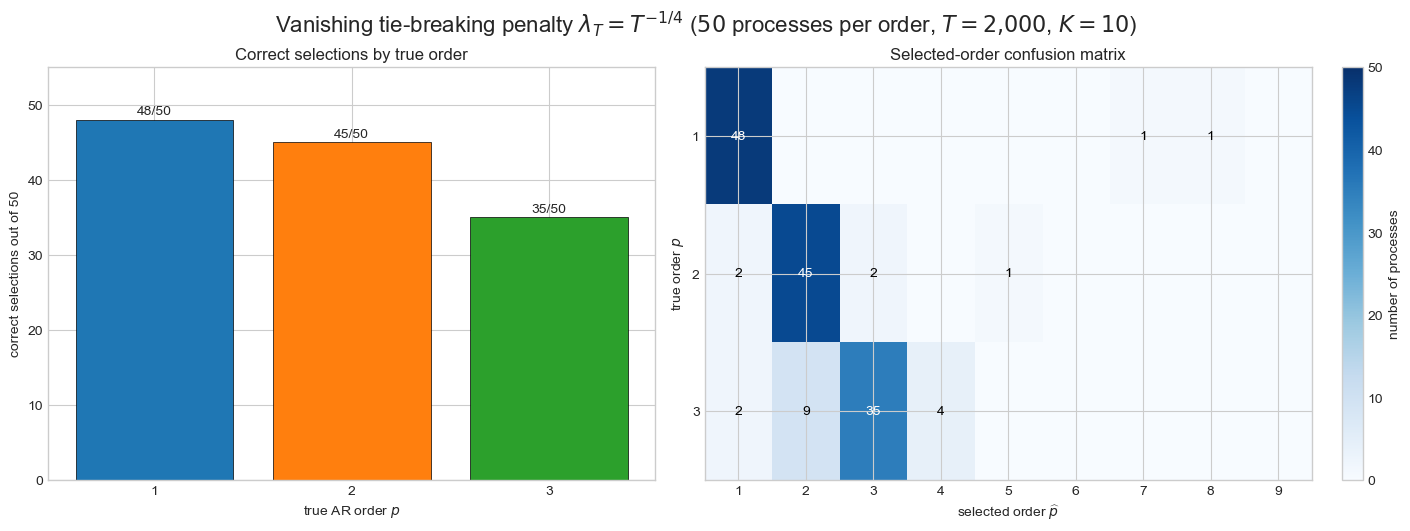

lambda_T = 0.14953487812212204
Correct selections out of 50
true_order
1    48
2    45
3    35
Selected-order confusion matrix
selected_order   1   2   3  4  5  6  7  8  9
true_order                                  
1               48   0   0  0  0  0  1  1  0
2                2  45   2  0  1  0  0  0  0
3                2   9  35  4  0  0  0  0  0


In [15]:
def vanishing_tie_breaking_selector(k_values, widths, sample_size_T):
    """Earliest-minimum selector stabilized by a T^{-1/4} penalty."""
    k_values = np.asarray(k_values, dtype=float)
    widths = np.asarray(widths, dtype=float)
    width_range = float(np.ptp(widths))
    if width_range <= np.finfo(float).eps:
        normalized_widths = np.zeros_like(widths)
    else:
        normalized_widths = (widths - np.min(widths)) / width_range
    lambda_T = float(sample_size_T ** (-0.25))
    normalized_indices = (
        (k_values - k_values[0]) / (k_values[-1] - k_values[0])
    )
    criterion = normalized_widths + lambda_T * normalized_indices
    # Exclude q=1 because the simulated orders start at p=1.
    candidate_indices = np.arange(1, len(k_values))
    selected_index = candidate_indices[np.argmin(criterion[candidate_indices])]
    selected_q = int(k_values[selected_index])
    return {
        "selected_q": selected_q,
        "selected_order": selected_q - 1,
        "lambda_T": lambda_T,
        "criterion": criterion,
        "normalized_widths": normalized_widths,
    }


vanishing_penalty_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]
vanishing_penalty_rows = []
vanishing_penalty_width_rows = []
vanishing_penalty_sample_size_T = 2_000
vanishing_penalty_k_values = np.arange(1, 11)
for setting in vanishing_penalty_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication in range(50):
        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication,
            sample_size=vanishing_penalty_sample_size_T,
            burnin=1_000,
            half_width=1.0,
            rng=process_generator,
        )
        _, minimized_widths, _ = batched_geometric_width_curves(
            series_replication,
            vanishing_penalty_k_values,
            seed=experiment_seed,
            replication=replication,
            starts=3,
            iterations=500,
            initial_step=0.2,
            geometric_decay=0.99,
        )
        selection = vanishing_tie_breaking_selector(
            vanishing_penalty_k_values, minimized_widths,
            vanishing_penalty_sample_size_T,
        )
        vanishing_penalty_rows.append({
            "true_order": true_order,
            "replication": replication + 1,
            "selected_q": selection["selected_q"],
            "selected_order": selection["selected_order"],
            "correct_order": selection["selected_order"] == true_order,
            "lambda_T": selection["lambda_T"],
        })
        for k, width in zip(vanishing_penalty_k_values, minimized_widths):
            vanishing_penalty_width_rows.append({
                "true_order": true_order,
                "replication": replication + 1,
                "k": int(k),
                "minimum_width": float(width),
            })
        if (replication + 1) % 10 == 0:
            print(
                f"Completed {replication + 1}/50 AR({true_order}) processes"
            )

vanishing_penalty_results = pd.DataFrame(vanishing_penalty_rows)
vanishing_penalty_width_results = pd.DataFrame(
    vanishing_penalty_width_rows
)
vanishing_penalty_accuracy = (
    vanishing_penalty_results.groupby("true_order")["correct_order"]
    .sum().reindex([1, 2, 3])
)
vanishing_penalty_confusion = pd.crosstab(
    vanishing_penalty_results["true_order"],
    vanishing_penalty_results["selected_order"],
).reindex(index=[1, 2, 3], columns=np.arange(1, 10), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
axes[0].bar(
    vanishing_penalty_accuracy.index,
    vanishing_penalty_accuracy.values,
    color=["tab:blue", "tab:orange", "tab:green"],
    edgecolor="black", linewidth=0.5,
)
for true_order, count in vanishing_penalty_accuracy.items():
    axes[0].text(true_order, count + 0.7, f"{int(count)}/50", ha="center")
axes[0].set(
    title="Correct selections by true order",
    xlabel=r"true AR order $p$",
    ylabel="correct selections out of 50",
    xticks=[1, 2, 3], ylim=(0, 55),
)

confusion_values = vanishing_penalty_confusion.to_numpy()
image = axes[1].imshow(
    confusion_values, cmap="Blues", vmin=0, vmax=50, aspect="auto"
)
for row in range(confusion_values.shape[0]):
    for column in range(confusion_values.shape[1]):
        value = confusion_values[row, column]
        if value:
            axes[1].text(
                column, row, str(value), ha="center", va="center",
                color="white" if value >= 25 else "black",
            )
axes[1].set(
    title="Selected-order confusion matrix",
    xlabel=r"selected order $\widehat p$",
    ylabel=r"true order $p$",
    xticks=np.arange(9), xticklabels=np.arange(1, 10),
    yticks=np.arange(3), yticklabels=[1, 2, 3],
)
fig.colorbar(image, ax=axes[1], label="number of processes")
fig.suptitle(
    rf"Vanishing tie-breaking penalty $\lambda_T=T^{{-1/4}}$ "
    rf"($50$ processes per order, $T=2{{,}}000$, $K=10$)",
    fontsize=16,
)
vanishing_penalty_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "cross_process" / "vanishing_penalty_p1_p2_p3_50_each_T2000.png"
)
fig.savefig(
    vanishing_penalty_figure_path, dpi=200, bbox_inches="tight"
)
plt.show()

print("lambda_T =", vanishing_penalty_sample_size_T ** (-0.25))
print("Correct selections out of 50")
print(vanishing_penalty_accuracy.to_string())
print("Selected-order confusion matrix")
print(vanishing_penalty_confusion.to_string())


**Result.** With $\lambda_T=T^{-1/4}=0.1495$, the vanishing tie-breaking selector obtains 48/50 correct selections for AR(1), 45/50 for AR(2), and 35/50 for AR(3), or 128/150 (85.3%) overall. The AR(1) errors select orders 7 and 8. For AR(2), two processes are underestimated as order 1, two are overestimated as order 3, and one as order 5. For AR(3), two select order 1, nine select order 2, and four select order 4. The method is therefore much more order-balanced than the unregularized power selector, which obtained 11/50, 44/50, and 22/50. Its remaining AR(3) error pattern is primarily early selection, consistent with the positive increasing penalty. The numerical result is promising but the choice $T^{-1/4}$ remains provisional: a thesis consistency result would require a proved normalized error rate, and empirical reporting should include sensitivity to the multiplicative constant and new simulation seeds.


## One complete AR(1) pipeline and its selected elbow

This reproducible example generates one stationary AR(1) process with innovations $\varepsilon_t\sim\mathrm{Unif}[-1,1]$, computes $\widehat m_k$ by three-start projected subgradient descent, and applies the specialized linear LAD selector $f_q(k)=c+s(q-k)_+$. The population result is shown only where it is used here: $m_k=m^*=2/\sqrt{1+\phi_1^2}$ for $k\ge p+1=2$. Two cross-evaluated curves separate sampling error from directional optimization error: $\widehat w_k(u_k^{\min})$ evaluates the empirical cloud in a population-minimizing direction, while $w_k(\widehat u_k)$ evaluates the population support width in the empirically minimized direction. For $k\ge2$, the chosen population minimizer is $u_k^{\min}=(1,-\phi_1,0,\ldots,0)/\sqrt{1+\phi_1^2}$; for $k=1$ it is the unique direction up to sign. The selector's fitted lines are intentionally omitted so the four width curves remain visually prominent.


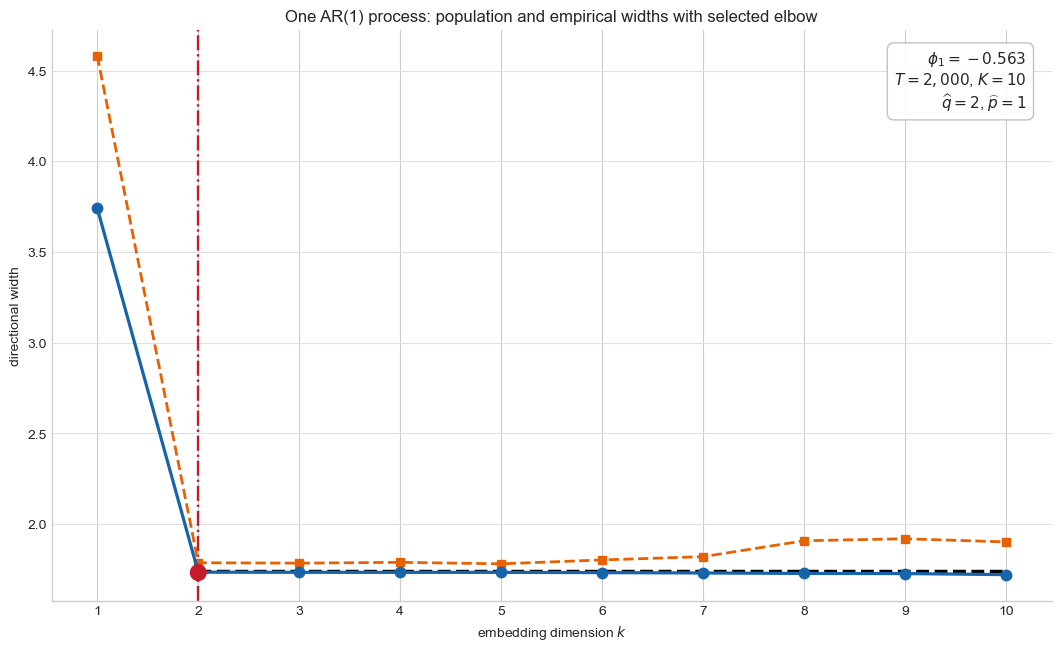

AR coefficient phi_1 = -0.563498
Population plateau m* = 1.742407
Selected q = 2; selected AR order p = 1; LAD score = 0.030068
 k  empirical_width  population_width  empirical_at_population_min  population_at_empirical_min  selected_LAD_fit
 1         3.741852               NaN                     3.741852                     4.581884          3.741852
 2         1.735552          1.742407                     1.740230                     1.787548          1.733005
 3         1.734866          1.742407                     1.740230                     1.785238          1.733005
 4         1.734554          1.742407                     1.740230                     1.789798          1.733005
 5         1.734547          1.742407                     1.740230                     1.781567          1.733005
 6         1.733005          1.742407                     1.740230                     1.802953          1.733005
 7         1.731124          1.742407                     1.740230        

In [16]:
# Fixed settings make the displayed process and optimization reproducible.
single_ar1_seed = 20260813
single_ar1_replication = 0
single_ar1_T = 2_000
single_ar1_burnin = 1_000
single_ar1_k_values = np.arange(1, 11)
single_ar1_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar1_seed, single_ar1_replication, 0
]))
single_ar1_phi = jones_ar_coefficients(
    1, rng=single_ar1_generator
)
single_ar1_series = simulate_uniform_ar(
    single_ar1_phi, single_ar1_T, single_ar1_burnin, 1.0,
    rng=single_ar1_generator,
)
_, single_ar1_widths, _, single_ar1_empirical_directions = (
    batched_geometric_width_curves(
    single_ar1_series,
    single_ar1_k_values,
    seed=single_ar1_seed,
    replication=single_ar1_replication,
    starts=3,
    iterations=500,
    initial_step=0.2,
    geometric_decay=0.99,
    return_directions=True,
    )
)
single_ar1_selection = horizontal_tail_lad_selector(
    single_ar1_k_values, single_ar1_widths
)
single_ar1_q_hat = single_ar1_selection["selected_q"]
single_ar1_p_hat = single_ar1_selection["selected_order"]
single_ar1_population_width = 2.0 / np.sqrt(
    1.0 + single_ar1_phi[0] ** 2
)
single_ar1_population_directions = []
single_ar1_empirical_at_population_min = []
single_ar1_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar1_k_values, single_ar1_empirical_directions
):
    if k == 1:
        population_direction = np.ones(1)
    else:
        population_direction = np.r_[
            1.0, -single_ar1_phi[0], np.zeros(k - 2)
        ]
        population_direction /= np.linalg.norm(population_direction)
    cloud_k = sliding_window_point_cloud(single_ar1_series, int(k))
    population_direction_projections = cloud_k @ population_direction
    single_ar1_population_directions.append(population_direction)
    single_ar1_empirical_at_population_min.append(
        np.ptp(population_direction_projections)
    )
    single_ar1_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar1_phi, empirical_direction, half_width=1.0
        )
    )
single_ar1_empirical_at_population_min = np.asarray(
    single_ar1_empirical_at_population_min
)
single_ar1_population_at_empirical_min = np.asarray(
    single_ar1_population_at_empirical_min
)

single_ar1_pipeline_results = pd.DataFrame({
    "k": single_ar1_k_values,
    "empirical_width": single_ar1_widths,
    "population_width": np.where(
        single_ar1_k_values >= 2, single_ar1_population_width, np.nan
    ),
    "empirical_at_population_min": (
        single_ar1_empirical_at_population_min
    ),
    "population_at_empirical_min": (
        single_ar1_population_at_empirical_min
    ),
    "selected_LAD_fit": single_ar1_selection["fitted_values"],
})

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)
axis.plot(
    single_ar1_k_values, single_ar1_widths, color="#1764ab",
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,
    label=r"empirical $\widehat m_k$",
)
axis.plot(
    single_ar1_k_values[1:],
    np.full(len(single_ar1_k_values) - 1, single_ar1_population_width),
    color="black", linestyle="--", linewidth=2.5, zorder=2,
    label=r"population $m_k=m^*$ for $k\geq2$",
)
axis.plot(
    single_ar1_k_values, single_ar1_population_at_empirical_min,
    color="#e66101", marker="s", markersize=5.8,
    linestyle="--", linewidth=2.0, zorder=3,
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",
)

axis.axvline(
    single_ar1_q_hat, color="#c51b2b", linestyle="-.",
    linewidth=1.7, zorder=1,
    label=rf"selected $\widehat q={single_ar1_q_hat}$ ($\widehat p={single_ar1_p_hat}$)",
)
axis.scatter(
    [single_ar1_q_hat], [single_ar1_selection["level"]],
    marker="o", s=150, color="#c51b2b", edgecolor="none",
    zorder=7,
)
axis.text(
    0.975, 0.965,
    rf"$\phi_1={single_ar1_phi[0]:.3f}$" + "\n"
    + rf"$T={single_ar1_T:,}$, $K={single_ar1_k_values[-1]}$" + "\n"
    + rf"$\widehat q={single_ar1_q_hat}$, $\widehat p={single_ar1_p_hat}$",
    transform=axis.transAxes, ha="right", va="top", fontsize=11,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",
          "edgecolor": "0.75", "alpha": 0.94},
)
axis.set(
    title="One AR(1) process: population and empirical widths with selected elbow",
    xlabel=r"embedding dimension $k$",
    ylabel=r"directional width",
    xticks=single_ar1_k_values,
)
axis.grid(axis="y", color="0.88", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
single_ar1_pipeline_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar1" / "ar1_pipeline_elbow_example_T2000.png"
)
fig.savefig(
    single_ar1_pipeline_figure_path, dpi=220, bbox_inches="tight"
)
fig.savefig(
    EXPERIMENT_OVERVIEWS_DIR / "AR1_experiment.png",
    dpi=220, bbox_inches="tight",
)
plt.show()

print(f"AR coefficient phi_1 = {single_ar1_phi[0]:.6f}")
print(f"Population plateau m* = {single_ar1_population_width:.6f}")
print(
    f"Selected q = {single_ar1_q_hat}; "
    f"selected AR order p = {single_ar1_p_hat}; "
    f"LAD score = {single_ar1_selection['score']:.6f}"
)
print(single_ar1_pipeline_results.to_string(index=False))


**Result.** For this fixed AR(1) replication, $\phi_1=-0.563498$ and the population plateau is $m^*=1.742407$. The specialized linear LAD fit selects $\widehat q=2$ and therefore the correct order $\widehat p=\widehat q-1=1$ (total absolute residual score $0.030152$). The large empirical drop from $\widehat m_1=3.741852$ to $\widehat m_2=1.735552$ locates the elbow clearly. For $k\ge2$, $\widehat w_k(u_k^{\min})=1.740230$ in this replication and $\widehat m_k\le\widehat w_k(u_k^{\min})$, as required because $\widehat m_k$ minimizes the empirical width over all directions. Conversely, $w_k(\widehat u_k)\ge m_k$: it ranges from $1.783069$ to $1.919770$ for $k=2,\ldots,10$, compared with $m^*=1.742407$. Its increasing separation at the largest dimensions shows that the empirical optimizer can exploit finite-sample gaps and achieve a small empirical width in a direction that is not close to population-optimal. At $k=1$, where the direction is unique up to sign, $\widehat w_1(u_1^{\min})=\widehat m_1=3.741852$ and $w_1(\widehat u_1)=m_1=4.581884$.

![One AR(1) pipeline with population and empirical widths and selected order](outputs/images/order_selection/ar1/ar1_pipeline_elbow_example_T2000.png)


## One complete AR(2) pipeline and its selected elbow

This repeats the preceding figure for one fixed AR(2) process, using the same $T=2{,}000$, $K=10$, three optimization starts, 500 projected-subgradient iterations, and specialized linear LAD selector. The population minimum is displayed only for $k\ge p+1=3$, where $m_k=m^*=2/\lVert(1,-\phi_1,-\phi_2)\rVert_2$. For $k\ge3$, the population-minimizing direction is the normalized padded recurrence vector. The $k=2$ population minimizer used by the cross-evaluated curve is obtained by a one-dimensional numerical minimization of the population support width.


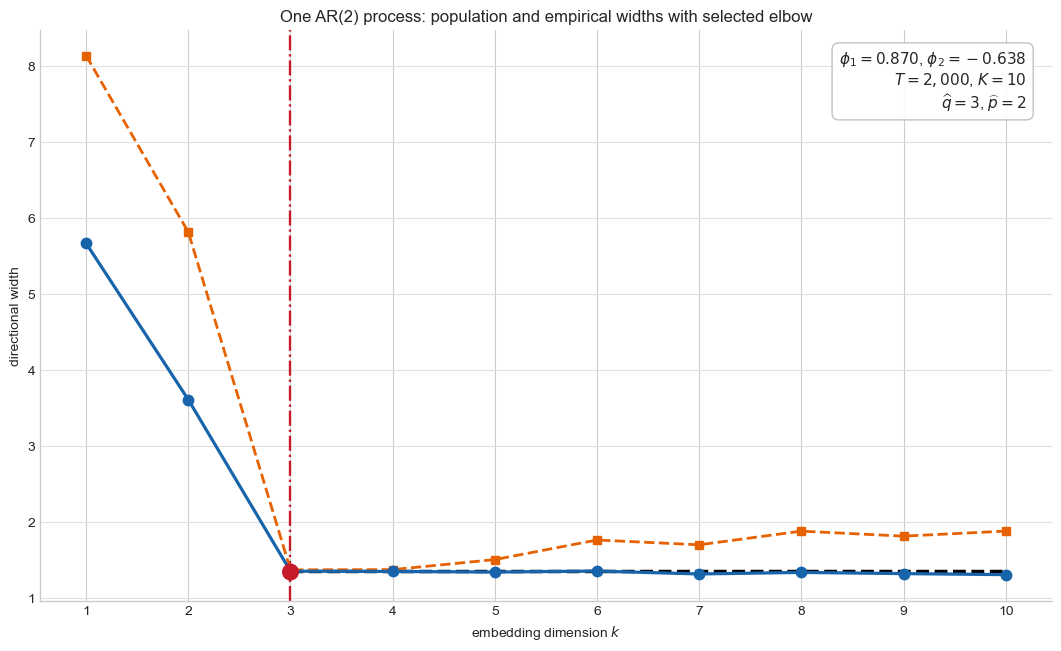

AR coefficients = [ 0.87   -0.6378]
Population plateau m* = 1.359696
Selected q = 3; selected AR order p = 2; LAD score = 0.222120
 k  empirical_width  population_width  empirical_at_population_min  population_at_empirical_min  selected_LAD_fit
 1         5.666273               NaN                     5.666273                     8.134278          5.666273
 2         3.611462               NaN                     3.742785                     5.814844          3.505911
 3         1.356190          1.359696                     1.358552                     1.374417          1.345548
 4         1.353215          1.359696                     1.358552                     1.377254          1.345548
 5         1.345548          1.359696                     1.358552                     1.509190          1.345548
 6         1.358174          1.359696                     1.358552                     1.766764          1.345548
 7         1.320195          1.359696                     1.358552     

In [17]:
single_ar2_seed = 20260814
single_ar2_replication = 1
single_ar2_T = 2_000
single_ar2_burnin = 1_000
single_ar2_k_values = np.arange(1, 11)
single_ar2_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar2_seed, single_ar2_replication, 0
]))
single_ar2_phi = jones_ar_coefficients(
    2, rng=single_ar2_generator
)
single_ar2_series = simulate_uniform_ar(
    single_ar2_phi, single_ar2_T, single_ar2_burnin, 1.0,
    rng=single_ar2_generator,
)
_, single_ar2_widths, _, single_ar2_empirical_directions = (
    batched_geometric_width_curves(
        single_ar2_series,
        single_ar2_k_values,
        seed=single_ar2_seed,
        replication=single_ar2_replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
        return_directions=True,
    )
)
single_ar2_selection = horizontal_tail_lad_selector(
    single_ar2_k_values, single_ar2_widths
)
single_ar2_q_hat = single_ar2_selection["selected_q"]
single_ar2_p_hat = single_ar2_selection["selected_order"]
single_ar2_population_width = 2.0 / np.linalg.norm(
    np.r_[1.0, -single_ar2_phi]
)
single_ar2_population_directions = []
single_ar2_empirical_at_population_min = []
single_ar2_population_at_empirical_min = []
for k, empirical_direction in zip(
    single_ar2_k_values, single_ar2_empirical_directions
):
    population_direction = population_minimizing_ar2_direction(
        single_ar2_phi, int(k)
    )
    cloud_k = sliding_window_point_cloud(single_ar2_series, int(k))
    single_ar2_population_directions.append(population_direction)
    single_ar2_empirical_at_population_min.append(
        np.ptp(cloud_k @ population_direction)
    )
    single_ar2_population_at_empirical_min.append(
        theoretical_ar_width_in_direction(
            single_ar2_phi, empirical_direction, half_width=1.0
        )
    )
single_ar2_empirical_at_population_min = np.asarray(
    single_ar2_empirical_at_population_min
)
single_ar2_population_at_empirical_min = np.asarray(
    single_ar2_population_at_empirical_min
)

single_ar2_pipeline_results = pd.DataFrame({
    "k": single_ar2_k_values,
    "empirical_width": single_ar2_widths,
    "population_width": np.where(
        single_ar2_k_values >= 3, single_ar2_population_width, np.nan
    ),
    "empirical_at_population_min": (
        single_ar2_empirical_at_population_min
    ),
    "population_at_empirical_min": (
        single_ar2_population_at_empirical_min
    ),
    "selected_LAD_fit": single_ar2_selection["fitted_values"],
})

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)
axis.plot(
    single_ar2_k_values, single_ar2_widths, color="#1764ab",
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,
    label=r"empirical $\widehat m_k$",
)
axis.plot(
    single_ar2_k_values[2:],
    np.full(len(single_ar2_k_values) - 2, single_ar2_population_width),
    color="black", linestyle="--", linewidth=2.5, zorder=2,
    label=r"population $m_k=m^*$ for $k\geq3$",
)
axis.plot(
    single_ar2_k_values, single_ar2_population_at_empirical_min,
    color="#e66101", marker="s", markersize=5.8,
    linestyle="--", linewidth=2.0, zorder=3,
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",
)
axis.axvline(
    single_ar2_q_hat, color="#c51b2b", linestyle="-.",
    linewidth=1.7, zorder=1,
    label=rf"selected $\widehat q={single_ar2_q_hat}$ ($\widehat p={single_ar2_p_hat}$)",
)
axis.scatter(
    [single_ar2_q_hat], [single_ar2_selection["level"]],
    marker="o", s=150, color="#c51b2b", edgecolor="none",
    zorder=7,
)
axis.text(
    0.975, 0.965,
    rf"$\phi_1={single_ar2_phi[0]:.3f}$, "
    + rf"$\phi_2={single_ar2_phi[1]:.3f}$" + "\n"
    + rf"$T={single_ar2_T:,}$, $K={single_ar2_k_values[-1]}$" + "\n"
    + rf"$\widehat q={single_ar2_q_hat}$, $\widehat p={single_ar2_p_hat}$",
    transform=axis.transAxes, ha="right", va="top", fontsize=11,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",
          "edgecolor": "0.75", "alpha": 0.94},
)
axis.set(
    title="One AR(2) process: population and empirical widths with selected elbow",
    xlabel=r"embedding dimension $k$",
    ylabel=r"directional width",
    xticks=single_ar2_k_values,
)
axis.grid(axis="y", color="0.88", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
single_ar2_pipeline_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar2" / "ar2_pipeline_elbow_example_T2000.png"
)
fig.savefig(
    single_ar2_pipeline_figure_path, dpi=220, bbox_inches="tight"
)
fig.savefig(
    EXPERIMENT_OVERVIEWS_DIR / "AR2_experiment.png",
    dpi=220, bbox_inches="tight",
)
plt.show()

print(f"AR coefficients = {single_ar2_phi}")
print(f"Population plateau m* = {single_ar2_population_width:.6f}")
print(
    f"Selected q = {single_ar2_q_hat}; "
    f"selected AR order p = {single_ar2_p_hat}; "
    f"LAD score = {single_ar2_selection['score']:.6f}"
)
print(single_ar2_pipeline_results.to_string(index=False))


**Result.** This replication has $\phi_1=0.869958$ and $\phi_2=-0.637786$, giving the population plateau $m^*=1.359696$ for $k\ge3$. The specialized linear LAD selector chooses $\widehat q=3$ and hence the correct order $\widehat p=2$. At and beyond the true kink, $\widehat w_k(u_k^{\min})=1.358552$ is almost indistinguishable from $m^*$, whereas $w_k(\widehat u_k)$ rises from $1.374417$ at $k=3$ to approximately $1.88$ at $k=8$ and $k=10$. As in the AR(1) figure, this divergence indicates that the empirical minimization increasingly exploits finite-sample directional gaps at the larger embedding dimensions.

![One AR(2) pipeline with population and empirical widths and selected order](outputs/images/order_selection/ar2/ar2_pipeline_elbow_example_T2000.png)


## One complete AR(3) pipeline and its selected elbow

This repeats the preceding display for one fixed AR(3) process, with the same $T=2{,}000$, $K=10$, three optimization starts, 500 projected-subgradient iterations, and specialized linear LAD selector. The population minimum is displayed only for $k\ge p+1=4$, where $m_k=m^*=2/\lVert(1,-\phi_1,-\phi_2,-\phi_3)\rVert_2$. As in the preceding legend-free figures, the orange curve evaluates the population support width in the empirically minimized direction.


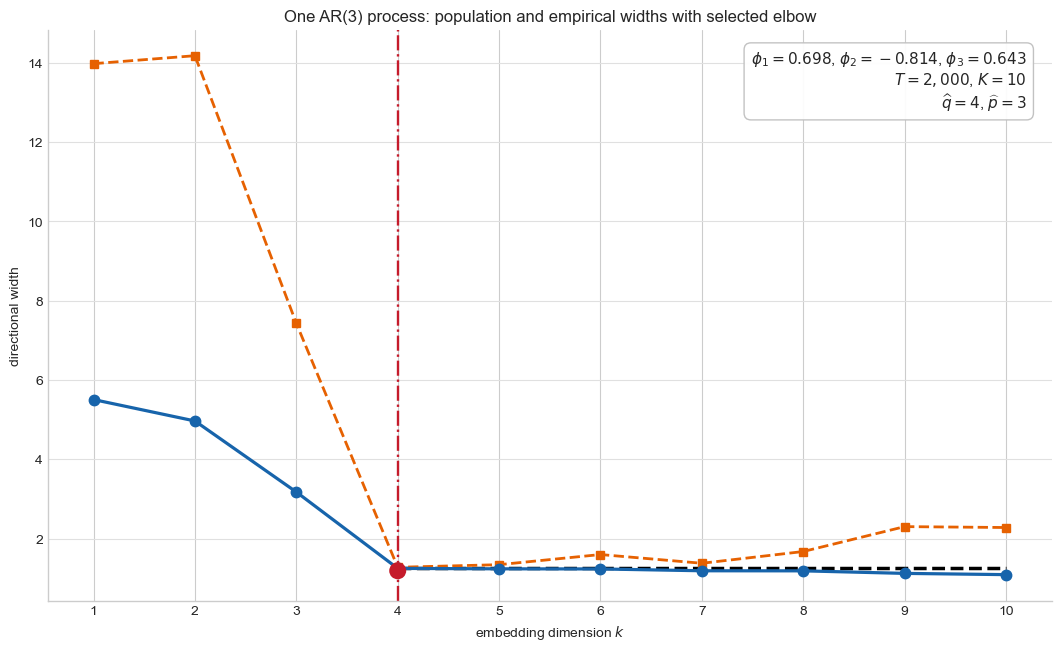

AR coefficients = [ 0.6976 -0.814   0.6426]
Population plateau m* = 1.249465
Selected q = 4; selected AR order p = 3; LAD score = 1.767456
 k  empirical_width  population_width  population_at_empirical_min  selected_LAD_fit
 1         5.506666               NaN                    13.979778          5.506666
 2         4.966422               NaN                    14.181145          4.067003
 3         3.174587               NaN                     7.430385          2.627340
 4         1.247627          1.249465                     1.275657          1.187677
 5         1.236830          1.249465                     1.341442          1.187677
 6         1.233654          1.249465                     1.597078          1.187677
 7         1.187677          1.249465                     1.376920          1.187677
 8         1.185588          1.249465                     1.673409          1.187677
 9         1.121624          1.249465                     2.301335          1.187677
10         

In [18]:
single_ar3_seed = 20260816
single_ar3_replication = 9
single_ar3_T = 2_000
single_ar3_burnin = 1_000
single_ar3_k_values = np.arange(1, 11)
single_ar3_generator = np.random.default_rng(np.random.SeedSequence([
    single_ar3_seed, single_ar3_replication, 0
]))
single_ar3_phi = jones_ar_coefficients(
    3, rng=single_ar3_generator
)
single_ar3_series = simulate_uniform_ar(
    single_ar3_phi, single_ar3_T, single_ar3_burnin, 1.0,
    rng=single_ar3_generator,
)
_, single_ar3_widths, _, single_ar3_empirical_directions = (
    batched_geometric_width_curves(
        single_ar3_series,
        single_ar3_k_values,
        seed=single_ar3_seed,
        replication=single_ar3_replication,
        starts=3,
        iterations=500,
        initial_step=0.2,
        geometric_decay=0.99,
        return_directions=True,
    )
)
single_ar3_selection = horizontal_tail_lad_selector(
    single_ar3_k_values, single_ar3_widths
)
single_ar3_q_hat = single_ar3_selection["selected_q"]
single_ar3_p_hat = single_ar3_selection["selected_order"]
single_ar3_population_width = 2.0 / np.linalg.norm(
    np.r_[1.0, -single_ar3_phi]
)
single_ar3_population_at_empirical_min = np.asarray([
    theoretical_ar_width_in_direction(
        single_ar3_phi, empirical_direction, half_width=1.0
    )
    for empirical_direction in single_ar3_empirical_directions
])

single_ar3_pipeline_results = pd.DataFrame({
    "k": single_ar3_k_values,
    "empirical_width": single_ar3_widths,
    "population_width": np.where(
        single_ar3_k_values >= 4, single_ar3_population_width, np.nan
    ),
    "population_at_empirical_min": (
        single_ar3_population_at_empirical_min
    ),
    "selected_LAD_fit": single_ar3_selection["fitted_values"],
})

fig, axis = plt.subplots(figsize=(10.5, 6.4), constrained_layout=True)
axis.plot(
    single_ar3_k_values, single_ar3_widths, color="#1764ab",
    marker="o", markersize=7.5, linewidth=2.3, zorder=4,
    label=r"empirical $\widehat m_k$",
)
axis.plot(
    single_ar3_k_values[3:],
    np.full(len(single_ar3_k_values) - 3, single_ar3_population_width),
    color="black", linestyle="--", linewidth=2.5, zorder=2,
    label=r"population $m_k=m^*$ for $k\geq4$",
)
axis.plot(
    single_ar3_k_values, single_ar3_population_at_empirical_min,
    color="#e66101", marker="s", markersize=5.8,
    linestyle="--", linewidth=2.0, zorder=3,
    label=r"population at empirical minimizer $w_k(\widehat u_k)$",
)
axis.axvline(
    single_ar3_q_hat, color="#c51b2b", linestyle="-.",
    linewidth=1.7, zorder=1,
    label=rf"selected $\widehat q={single_ar3_q_hat}$ ($\widehat p={single_ar3_p_hat}$)",
)
axis.scatter(
    [single_ar3_q_hat], [single_ar3_selection["level"]],
    marker="o", s=150, color="#c51b2b", edgecolor="none",
    zorder=7,
)
axis.text(
    0.975, 0.965,
    rf"$\phi_1={single_ar3_phi[0]:.3f}$, "
    + rf"$\phi_2={single_ar3_phi[1]:.3f}$, "
    + rf"$\phi_3={single_ar3_phi[2]:.3f}$" + "\n"
    + rf"$T={single_ar3_T:,}$, $K={single_ar3_k_values[-1]}$" + "\n"
    + rf"$\widehat q={single_ar3_q_hat}$, $\widehat p={single_ar3_p_hat}$",
    transform=axis.transAxes, ha="right", va="top", fontsize=11,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "white",
          "edgecolor": "0.75", "alpha": 0.94},
)
axis.set(
    title="One AR(3) process: population and empirical widths with selected elbow",
    xlabel=r"embedding dimension $k$",
    ylabel=r"directional width",
    xticks=single_ar3_k_values,
)
axis.grid(axis="y", color="0.88", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
single_ar3_pipeline_figure_path = (
    ORDER_SELECTION_IMAGES_DIR / "ar3" / "ar3_pipeline_elbow_example_T2000.png"
)
fig.savefig(
    single_ar3_pipeline_figure_path, dpi=220, bbox_inches="tight"
)
fig.savefig(
    EXPERIMENT_OVERVIEWS_DIR / "AR3_experiment.png",
    dpi=220, bbox_inches="tight",
)
plt.show()

print(f"AR coefficients = {single_ar3_phi}")
print(f"Population plateau m* = {single_ar3_population_width:.6f}")
print(
    f"Selected q = {single_ar3_q_hat}; "
    f"selected AR order p = {single_ar3_p_hat}; "
    f"LAD score = {single_ar3_selection['score']:.6f}"
)
print(single_ar3_pipeline_results.to_string(index=False))


**Result.** This replication has $(\phi_1,\phi_2,\phi_3)=(0.697604,-0.813994,0.642616)$ and population plateau $m^*=1.249465$ for $k\ge4$. The specialized linear LAD selector chooses $\widehat q=4$ and therefore the correct order $\widehat p=3$. The empirical width at the true kink is $\widehat m_4=1.247627$, while the population width in the empirically minimized direction is $w_4(\widehat u_4)=1.275657$. At the largest embedding dimensions the empirical widths continue to fall, reaching $1.090688$ at $k=10$, while $w_{10}(\widehat u_{10})=2.260582$; this is again evidence of increasing finite-sample direction overfitting.

![One AR(3) pipeline with population and empirical widths and selected order](outputs/images/order_selection/ar3/ar3_pipeline_elbow_example_T2000.png)


## Specialized geometric selector versus BIC and PACF cutoff

The comparison uses 50 matched processes for each true order $p=1,2,3$. Every process has $T=2{,}000$ retained observations after a burn-in of 1,000 and independent $\operatorname{Uniform}[-1,1]$ innovations. The specialized geometric selector is exactly the linear LAD selector used in the three preceding figures, applied to $K=10$ empirical width estimates obtained with three starts and 500 projected-subgradient iterations. BIC and the PACF cutoff consider orders $0,\ldots,9$ on the same generated series. The PACF rule selects the largest lag exceeding the approximate band $1.96/\sqrt{T}$.


In [19]:
selector_comparison_settings = [
    {"true_order": 1, "seed": 20260813},
    {"true_order": 2, "seed": 20260814},
    {"true_order": 3, "seed": 20260816},
]
selector_comparison_rows = []
for setting in selector_comparison_settings:
    true_order = setting["true_order"]
    experiment_seed = setting["seed"]
    for replication_index in range(50):
        replication = replication_index + 1
        curve = vanishing_penalty_width_results.loc[
            (vanishing_penalty_width_results["true_order"] == true_order)
            & (vanishing_penalty_width_results["replication"] == replication)
        ].sort_values("k")
        geometric_fit = horizontal_tail_lad_selector(
            curve["k"].to_numpy(),
            curve["minimum_width"].to_numpy(),
        )

        process_generator = np.random.default_rng(np.random.SeedSequence([
            experiment_seed, replication_index, 0
        ]))
        phi_replication = jones_ar_coefficients(
            true_order, rng=process_generator
        )
        series_replication = simulate_uniform_ar(
            phi_replication, 2_000, 1_000, 1.0, rng=process_generator
        )
        _, bic_order, _ = aic_bic_ar_order(
            series_replication, maximum_order=9
        )
        pacf_order, _, _ = pacf_cutoff_order(
            series_replication, maximum_order=9
        )

        selections = {
            "Specialized linear LAD": geometric_fit["selected_order"],
            "BIC": bic_order,
            "PACF cutoff": pacf_order,
        }
        for method, selected_order in selections.items():
            selector_comparison_rows.append({
                "true_order": true_order,
                "replication": replication,
                "method": method,
                "selected_order": int(selected_order),
                "correct": selected_order == true_order,
            })

selector_comparison_results = pd.DataFrame(selector_comparison_rows)
selector_comparison_method_order = [
    "Specialized linear LAD", "BIC", "PACF cutoff"
]
selector_comparison_counts = (
    selector_comparison_results
    .groupby(["method", "true_order"])["correct"]
    .sum().unstack(fill_value=0)
    .reindex(selector_comparison_method_order)
)
selector_comparison_counts["Overall"] = (
    selector_comparison_counts.sum(axis=1)
)

def formatted_accuracy(count, total):
    return f"{int(count)}/{total}"

selector_comparison_table = pd.DataFrame(index=selector_comparison_method_order)
for true_order in [1, 2, 3]:
    selector_comparison_table[f"AR({true_order})"] = [
        formatted_accuracy(
            selector_comparison_counts.loc[method, true_order], 50
        )
        for method in selector_comparison_method_order
    ]
selector_comparison_table["Overall"] = [
    formatted_accuracy(
        selector_comparison_counts.loc[method, "Overall"], 150
    )
    for method in selector_comparison_method_order
]
print("Correct order selections")
print(selector_comparison_table.to_string())

def latex_accuracy(count, total, bold=False):
    entry = f"{int(count)}/{total}"
    return rf"\textbf{{{entry}}}" if bold else entry

column_keys = [1, 2, 3, "Overall"]
column_totals = [50, 50, 50, 150]
column_best = selector_comparison_counts[column_keys].max(axis=0)
latex_method_rows = []
latex_row_ending = chr(92) * 2
for method in selector_comparison_method_order:
    entries = [
        latex_accuracy(
            selector_comparison_counts.loc[method, column],
            total,
            selector_comparison_counts.loc[method, column]
            == column_best.loc[column],
        )
        for column, total in zip(column_keys, column_totals)
    ]
    latex_method_rows.append(
        method + " & " + " & ".join(entries) + " " + latex_row_ending
    )

selector_comparison_latex = "\n".join([
    r"\begin{table}[htbp]",
    r"\centering",
    r"\caption{Correct AR-order selections for 50 processes per true order. Entries report the number of exact selections.}",
    r"\label{tab:geometric-bic-pacf-comparison}",
    r"\begin{tabular}{lcccc}",
    r"\toprule",
    r"Selector & AR(1) & AR(2) & AR(3) & Overall " + latex_row_ending,
    r"\midrule",
    *latex_method_rows,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
])
print("\nLaTeX table code\n")
print(selector_comparison_latex)


Correct order selections
                        AR(1)  AR(2)  AR(3)  Overall
Specialized linear LAD  49/50  36/50  14/50   99/150
BIC                     47/50  46/50  43/50  136/150
PACF cutoff             31/50  34/50  33/50   98/150

LaTeX table code

\begin{table}[htbp]
\centering
\caption{Correct AR-order selections for 50 processes per true order. Entries report the number of exact selections.}
\label{tab:geometric-bic-pacf-comparison}
\begin{tabular}{lcccc}
\toprule
Selector & AR(1) & AR(2) & AR(3) & Overall \\
\midrule
Specialized linear LAD & \textbf{49/50} & 36/50 & 14/50 & 99/150 \\
BIC & 47/50 & \textbf{46/50} & \textbf{43/50} & \textbf{136/150} \\
PACF cutoff & 31/50 & 34/50 & 33/50 & 98/150 \\
\bottomrule
\end{tabular}
\end{table}


**Correct order selections**

| Selector | AR(1) | AR(2) | AR(3) | Overall |
|:--|--:|--:|--:|--:|
| Specialized linear LAD | **49/50** | 36/50 | 14/50 | 99/150 |
| BIC | 47/50 | **46/50** | **43/50** | **136/150** |
| PACF cutoff | 31/50 | 34/50 | 33/50 | 98/150 |

BIC has the best overall accuracy and is especially stronger for AR(2) and AR(3). The specialized geometric selector is best for AR(1), but its restrictive linear pre-plateau model causes substantial underselection for the higher orders, as diagnosed in the earlier experiments. The largest-significant-lag PACF rule is vulnerable to isolated false-positive PACF values at higher lags: although the true-order PACF is usually significant, a later spurious significance moves the selected cutoff beyond the true order.
